# 295. Does any kmerseek setting reach ice-binding proteins of other lineages from one query?

This notebook holds the whole convergence test. Sections 1-7 are the ice-binding
proteins, the one class searched as a benchmark. Section 8 is the truth sets for three
more classes, adhesive, shell-matrix and silk proteins. Section 11 searches one adhesive
protein, mussel foot protein 1, as a case study.

Ice-binding proteins, also called antifreeze proteins, stop ice crystals growing in an
animal, plant or microbe that lives below freezing. They arose separately several times:
in fish, type I, type II, type III and the antifreeze glycoprotein AFGP come from
different ancestral genes, and insects, plants, bacteria and fungi evolved their own. So
two ice-binding proteins from different lineages may share a job and a physicochemical
pattern without sharing that function by ancestry. A taxonomic lineage boundary alone
does not establish independent origins; section 4 checks the family annotations of hits.

**The question.** kmerseek matches k-mers in a reduced alphabet, so a hydrophobic and
polar pattern can match where the residues do not. If that is enough to carry a pattern
across lineages, then one ice-binding protein should reach the others. The test is
whether it does so better than methods that need no search at all.

**The decision this informs.** Whether the paper can claim that kmerseek finds proteins
that share a physicochemical pattern without shared ancestry. That claim is the whole
case for searching in a reduced alphabet rather than filtering a protein by its
composition. If a scan with no search reaches the same proteins, the search adds nothing
here and the claim comes out of the paper.

**The decision rule, fixed before the run** (from the task brief, 2026-10-14, and
unchanged since). PASS needs all three:

1. The kmerseek setting is chosen on the odd-numbered query lineages (1 fish type I,
   3 fish type II, 5 insects, 7 bacteria) and reported on the even-numbered ones
   (2 AFGP, 4 fish type III). Plants have no reviewed entry, so the even half is two
   lineages and both must pass.
2. On both held-out lineages, the chosen setting's cross-lineage recall beats the
   composition scan and the period scan by at least 0.10.
3. For those queries, the median number of ice-binding proteins a null draw reaches is at
   most 10% of the number the real query reaches.

Higher recall is better; 0 means the method reached no ice-binding protein of any other
lineage.

**The data.** The convergence-afp pipeline
([nextflow-runs/convergence-afp](../nextflow-runs/convergence-afp), PR 141), run on
Sherlock 15-16 October 2026 and scored on 17 October; rescored on 20 October (Slurm job
48646822, `scripts/convergence_afp_rescore.sbatch`) after all 10 phmmer and 10 jackhmmer
chunks, 246 queries, were put back by `scripts/convergence_recover_hmmer_chunks.sh`.
Before that, those two tools held one chunk of 24 queries, because every chunk was
published under one file name. Every method ranked all 575_748 entries of reviewed
Swiss-Prot release 2026_03 (FASTA MD5 `bc9d398533e6df582b563c6c03093bd0`) for every
query. kmerseek is 0.4 at commit
[3c353d4](https://github.com/seanome/kmerseek/pull/141), with the Karlin-Altschul
E-value path on, over the 230 settings of the dark-set midi run. A setting is one
alphabet, k-size, scaled value, low-complexity mask and mismatch penalty.

**Queries.** One reviewed entry per lineage, the one with the most experimental evidence
lines: P04002 (winter flounder, type I), P02732 (bald rockcod, AFGP), A0ZT93 (sea
poacher, type II), P07457 (ocean pout, type III), Q9GSA6 (spruce budworm, insect) and
H7FWB6 (*Flavobacterium frigoris*, bacterial). Each also got 20 draws of two controls:
null A shuffles the query's residues, keeping its composition; null B reorders positions
inside the repeat unit, keeping composition and repeat period but changing the word.

**How a method is compared.** There are no synthetic decoys. For each ranked list, the
threshold is the score of the first Swiss-Prot entry that is not an ice-binding protein
at all, and recall is the share of other-lineage ice-binding proteins scoring better than
that. A hit on the query's own lineage is never counted, in either the numerator or the
denominator. The scoring code is
[nextflow-runs/convergence-afp/bin/score.py](../nextflow-runs/convergence-afp/bin/score.py).

In [1]:
import json
import os
import re
import sys
import textwrap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

sys.path.insert(0, str(Path.cwd()))
import pubfig as pf

pf.use_style()

SCORED = Path(
    os.environ.get("CONVERGENCE_SCORED", "~/data/convergence-afp/scored")
).expanduser()
TRUTH_DIR = Path("../data/convergence_afp")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

metrics = pl.read_csv(SCORED / "metrics.tsv", separator="\t")
grid = pl.read_csv(SCORED / "grid.tsv", separator="\t")
verdict = json.loads((SCORED / "verdict.json").read_text())
afdb = pl.read_csv(SCORED / "afdb_coverage.tsv", separator="\t")
truth = pl.read_csv(TRUTH_DIR / "truth_set.tsv", separator="\t")
queries = pl.read_csv(TRUTH_DIR / "queries.tsv", separator="\t")
hits_md = (SCORED / "hits_residues.md").read_text()

# Real queries only, and only rows where a false positive set the threshold. A list with
# none has no recall: see bin/score.py.
real = metrics.filter((pl.col("kind") == "real") & pl.col("recall").is_not_null())
# Every setting the run was given, read from its own table: a setting whose E-value fit was
# refused writes no rows, so counting the metrics would miss it.
n_settings_total = pl.read_csv(
    "../nextflow-runs/convergence-afp/assets/kmerseek_settings.tsv", separator="\t"
).height

# One colour per method, kept for every figure in this notebook.
METHOD_COLOUR = {
    "kmerseek": pf.OKABE_ITO["blue"],
    "phmmer": pf.OKABE_ITO["vermillion"],
    "jackhmmer": pf.OKABE_ITO["orange"],
    "mmseqs2": pf.OKABE_ITO["reddish_purple"],
    "foldseek": pf.OKABE_ITO["bluish_green"],
    "composition": pf.OKABE_ITO["sky_blue"],
    "period": pf.OKABE_ITO["yellow"],
    "window": pf.OKABE_ITO["black"],
    "motif": pf.GREY,
}
METHOD_ORDER = [
    "kmerseek",
    "phmmer",
    "jackhmmer",
    "mmseqs2",
    "foldseek",
    "composition",
    "period",
    "window",
    "motif",
]
QUERY_LINEAGES = sorted(real["query_lineage"].unique())
TARGET_LINEAGES = sorted(truth["lineage"].unique())


def header(fig, tools, hypothesis, conclusion):
    """Tool, hypothesis and conclusion above the panels, with no empty band.

    pubfig builds figures with constrained layout, which reserves space for a suptitle
    but ignores subplots_adjust, so the header goes in the suptitle. The text is wrapped
    to the figure's own width: an unwrapped line runs off the page and over the panels.
    """
    n_chars = max(40, int(fig.get_figwidth() * 25.4 / 1.3))
    lines = []
    for label, text in [
        ("TOOLS", tools),
        ("HYPOTHESIS", hypothesis),
        ("CONCLUSION", conclusion),
    ]:
        lines += textwrap.wrap(f"{label}: {text}", n_chars)
    fig.suptitle("\n".join(lines), x=0.0, ha="left", va="bottom", fontsize=6)


def legend_in_axes(ax, ncol=1, loc="upper right"):
    """Legend in the panel's empty space.

    pubfig's shared legend goes in the band above the panels, which is where the header
    text goes, and the two overlapped.
    """
    ax.legend(loc=loc, ncol=ncol, frameon=False, fontsize=6)


# Every ranked list must hold every query, including the ones it reported nothing for.
# A list missing a query would make a median over the null draws a median over the draws
# that happened to hit something (bin/score.py, commit 653ddd1).
per_list = metrics.group_by("method", "setting_label", "overlap_min").len()
n_queries = metrics["query_id"].n_unique()
short = per_list.filter(pl.col("len") != n_queries)
assert (
    short.height == 0
), f"{short.height} ranked lists do not score all {n_queries} queries:\n{short}"
print(f"every one of the {per_list.height} ranked lists scores all {n_queries} queries")

print(
    f"metrics rows {metrics.height}, ranked lists {metrics['setting_label'].n_unique()}"
)
print(
    f"kmerseek settings {n_settings_total}, truth entries {truth.height}, queries {queries.height}"
)
print(f"verdict {verdict['verdict']}, chosen setting {verdict['chosen_setting']}")

every one of the 202 ranked lists scores all 246 queries
metrics rows 49692, ranked lists 200
kmerseek settings 230, truth entries 59, queries 6
verdict FAIL, chosen setting hsdm17.k6.s1.lcfalse.extend-c0.18


## 1. The truth set: 59 reviewed ice-binding proteins, and what Foldseek can see of them

Every reviewed UniProtKB entry matched by the keyword "Antifreeze protein" (KW-0047),
the Gene Ontology term "ice binding" (GO:0050825), or a protein-name search, in release
2026_03. The lineage comes from the entry's taxonomy, and for fish from the antifreeze
type in its family or name. `fish, type unknown` holds the three type IV proteins, which
UniProt places in the apolipoprotein family; they count as targets but have no query.

Two facts set the ceiling for the whole test. Plants have no reviewed entry, so there is
no plant query. And an entry with no AlphaFold model cannot be reached by Foldseek
searching structures, which is why panel b matters: 7 of the 8 insect entries, the spruce
budworm isoforms, have no model.

shape: (8, 4)
┌──────────────────────┬───────────┬──────────────────┬─────────────────┐
│ lineage              ┆ n_entries ┆ median_length_aa ┆ n_without_model │
│ ---                  ┆ ---       ┆ ---              ┆ ---             │
│ str                  ┆ u32       ┆ f64              ┆ i64             │
╞══════════════════════╪═══════════╪══════════════════╪═════════════════╡
│ 1 fish, type I AFP   ┆ 12        ┆ 82.0             ┆ 1               │
│ 2 fish, AFGP         ┆ 4         ┆ 25.0             ┆ 0               │
│ 3 fish, type II AFP  ┆ 3         ┆ 168.0            ┆ 0               │
│ 4 fish, type III AFP ┆ 19        ┆ 66.0             ┆ 0               │
│ 5 insects            ┆ 8         ┆ 110.0            ┆ 7               │
│ 7 bacteria           ┆ 4         ┆ 272.5            ┆ 0               │
│ 8 other              ┆ 6         ┆ 245.0            ┆ 1               │
│ fish, type unknown   ┆ 3         ┆ 125.0            ┆ 0               │
└──────────────────────┴

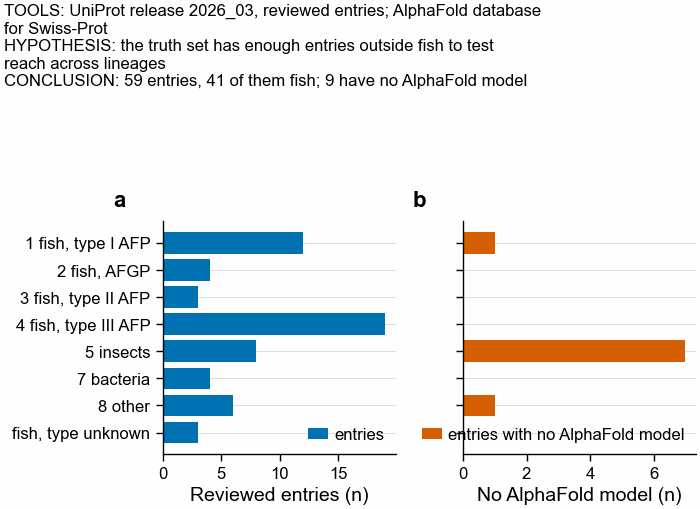

In [2]:
per_lineage = (
    truth.group_by("lineage")
    .agg(
        pl.len().alias("n_entries"), pl.col("Length").median().alias("median_length_aa")
    )
    .join(afdb.select("lineage", "n_without_model"), on="lineage", how="left")
    .sort("lineage")
)
print(per_lineage)
print()
print(
    queries.select("lineage", "Entry", "Protein names", "Length", "Organism").sort(
        "lineage"
    )
)

fig, axs = pf.figure(pf.ONE_COLUMN_MM, 55, ncols=2, sharey=True)
y = np.arange(per_lineage.height)
axs[0].barh(y, per_lineage["n_entries"], color=pf.OKABE_ITO["blue"], label="entries")
axs[1].barh(
    y,
    per_lineage["n_without_model"],
    color=pf.OKABE_ITO["vermillion"],
    label="entries with no AlphaFold model",
)
axs[0].set_yticks(y)
axs[0].set_yticklabels(per_lineage["lineage"])
axs[0].invert_yaxis()
axs[0].set_xlabel("Reviewed entries (n)")
axs[1].set_xlabel("No AlphaFold model (n)")
for ax in axs:
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[0], loc="lower right")
legend_in_axes(axs[1], loc="lower right")
header(
    fig,
    "UniProt release 2026_03, reviewed entries; AlphaFold database for Swiss-Prot",
    "the truth set has enough entries outside fish to test reach across lineages",
    f"{int(per_lineage['n_entries'].sum())} entries, "
    f"{int(per_lineage.filter(pl.col('lineage').str.starts_with('1 ') | pl.col('lineage').str.starts_with('2 ') | pl.col('lineage').str.starts_with('3 ') | pl.col('lineage').str.starts_with('4 ') | pl.col('lineage').str.starts_with('fish'))['n_entries'].sum())} of them fish; "
    f"{int(per_lineage['n_without_model'].sum())} have no AlphaFold model",
)
pf.save(fig, FIGURES / "295_SF1_truth_set_per_lineage_swissprot_2026_03")

## 2. What ran: 230 kmerseek settings, four existing tools and four scans with no search

A scan needs no search: it turns each protein into one description and ranks targets by
distance to the query's. The composition scan uses residue frequencies, in 20 letters and
in each kmerseek alphabet's classes. The period scan uses the hydrophobic-polar
autocorrelation and the Eisenberg hydrophobic moment. The hydropathy window scan slides a
Kyte-Doolittle window of 9 or 19 residues and matches the two profiles at their best
offset; because a short target matches a long query's best stretch over very few windows,
it is run at four minimum-overlap cutoffs and gets the best of them. The known-motif scan
applies the published repeat consensus for AFGP, fish type I and the spruce budworm.

Of the 230 kmerseek settings, 66 could not be searched at all: their Karlin-Altschul fit
was refused, so no E-value exists to rank by. Those are absent below rather than counted
as zero.

shape: (9, 5)
┌─────────────┬──────────────┬────────────────┬──────────────────────────┬─────────────┐
│ method      ┆ ranked_lists ┆ queries_ranked ┆ most_cross_lineage_found ┆ best_recall │
│ ---         ┆ ---          ┆ ---            ┆ ---                      ┆ ---         │
│ enum        ┆ u32          ┆ u32            ┆ i64                      ┆ f64         │
╞═════════════╪══════════════╪════════════════╪══════════════════════════╪═════════════╡
│ kmerseek    ┆ 164          ┆ 6              ┆ 5                        ┆ 0.090909    │
│ phmmer      ┆ 1            ┆ 5              ┆ 5                        ┆ 0.090909    │
│ jackhmmer   ┆ 1            ┆ 5              ┆ 5                        ┆ 0.090909    │
│ mmseqs2     ┆ 1            ┆ 6              ┆ 5                        ┆ 0.090909    │
│ foldseek    ┆ 2            ┆ 6              ┆ 5                        ┆ 0.090909    │
│ composition ┆ 20           ┆ 6              ┆ 7                        ┆ 0.127273    │
│ perio

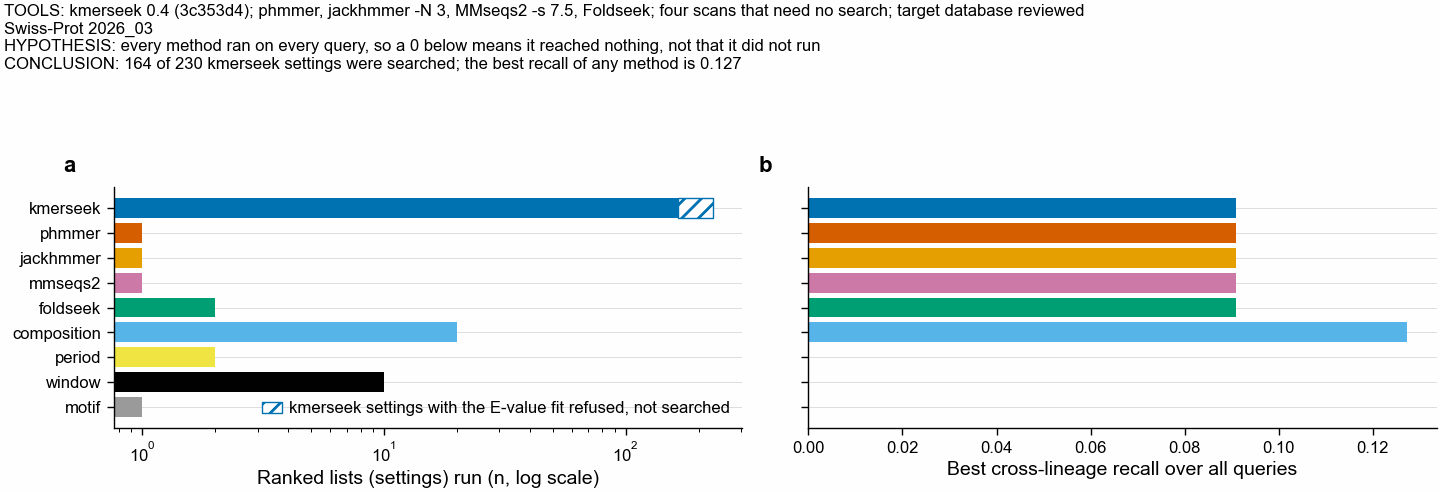

In [3]:
ran = (
    real.group_by("method")
    .agg(
        pl.col("setting_label").n_unique().alias("ranked_lists"),
        pl.col("query_id").n_unique().alias("queries_ranked"),
        pl.col("n_found").max().alias("most_cross_lineage_found"),
        pl.col("recall").max().alias("best_recall"),
    )
    .with_columns(pl.col("method").cast(pl.Enum(METHOD_ORDER)))
    .sort("method")
)
print(ran)
print()
print(
    "kmerseek settings with a usable E-value fit: "
    f"{real.filter(pl.col('method') == 'kmerseek')['setting_label'].n_unique()} of {n_settings_total}"
)

n_searched = real.filter(pl.col("method") == "kmerseek")["setting_label"].n_unique()
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 55, ncols=2, sharey=True)
y = np.arange(ran.height)
methods = [str(m) for m in ran["method"]]
axs[0].barh(y, ran["ranked_lists"], color=[METHOD_COLOUR[m] for m in methods])
k = methods.index("kmerseek")
axs[0].barh(
    k,
    n_settings_total - n_searched,
    left=n_searched,
    color="white",
    edgecolor=METHOD_COLOUR["kmerseek"],
    hatch="////",
    linewidth=0.5,
    label="kmerseek settings with the E-value fit refused, not searched",
)
axs[1].barh(y, ran["best_recall"], color=[METHOD_COLOUR[m] for m in methods])
axs[0].set_yticks(y)
axs[0].set_yticklabels(methods)
axs[0].invert_yaxis()
axs[0].set_xscale("log")
axs[0].set_xlabel("Ranked lists (settings) run (n, log scale)")
axs[1].set_xlabel("Best cross-lineage recall over all queries")
for ax in axs:
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[0], loc="lower right")
header(
    fig,
    "kmerseek 0.4 (3c353d4); phmmer, jackhmmer -N 3, MMseqs2 -s 7.5, Foldseek; four scans "
    "that need no search; target database reviewed Swiss-Prot 2026_03",
    "every method ran on every query, so a 0 below means it reached nothing, not that it "
    "did not run",
    f"{n_searched} of {n_settings_total} kmerseek settings were searched; the best recall of "
    f"any method is {float(ran['best_recall'].max()):.3f}",
)
pf.save(fig, FIGURES / "295_SF3_methods_run_swissprot_2026_03")

## 3. F1: the lineage grid. Only six squares off the diagonal are not zero

Rows are the query's lineage, columns the target's. A square holds how many ice-binding
proteins of that target lineage the query reached, taking the best of that method's
settings. The diagonal is grey because a hit on the query's own lineage is never counted:
only off-diagonal squares test reach across lineages.

Read it as a map of where any method gets out of its own lineage. Five methods reach the
same five fungal proteins from the bacterial query, and one scan reaches seven fish type I
proteins from the AFGP query. Every other square is zero.

shape: (6, 4)
┌─────────────┬───────────────┬────────────────────┬─────────┐
│ method      ┆ query_lineage ┆ target_lineage     ┆ n_found │
│ ---         ┆ ---           ┆ ---                ┆ ---     │
│ str         ┆ str           ┆ str                ┆ i64     │
╞═════════════╪═══════════════╪════════════════════╪═════════╡
│ composition ┆ 2 fish, AFGP  ┆ 1 fish, type I AFP ┆ 7       │
│ foldseek    ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ jackhmmer   ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ kmerseek    ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ mmseqs2     ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
│ phmmer      ┆ 7 bacteria    ┆ 8 other            ┆ 5       │
└─────────────┴───────────────┴────────────────────┴─────────┘


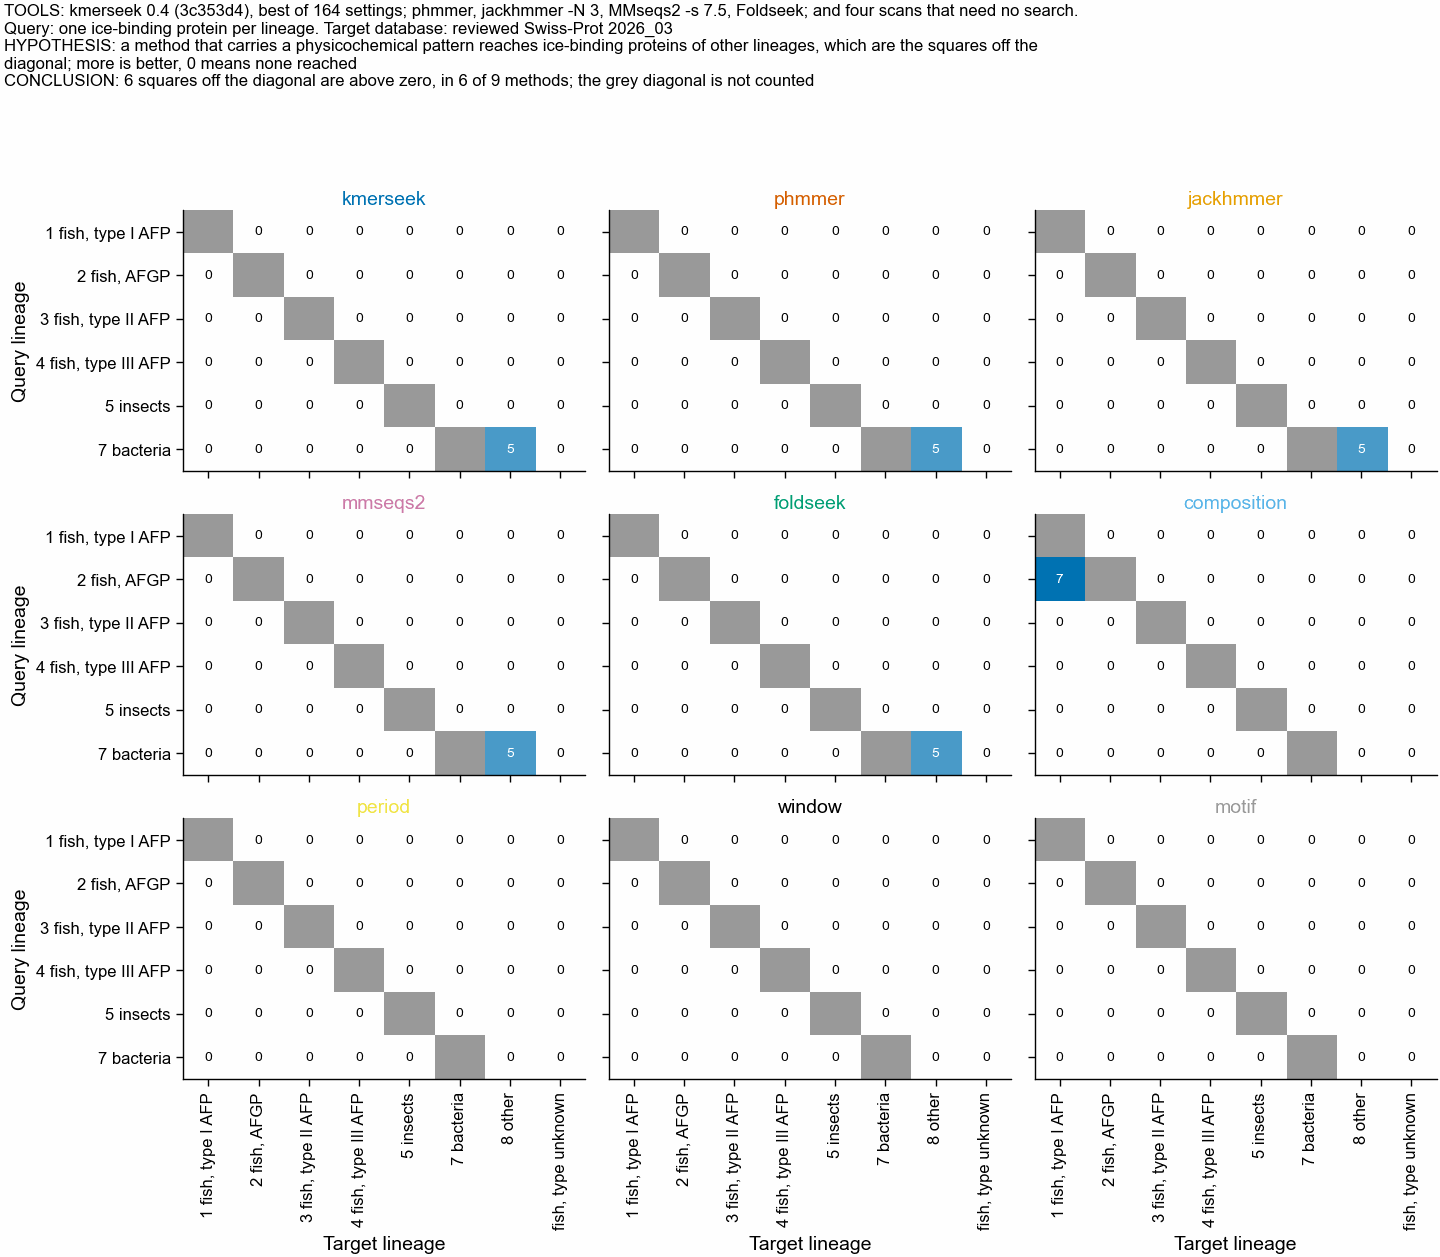

In [4]:
best_cell = grid.group_by("method", "query_lineage", "target_lineage").agg(
    pl.col("n_found").max().alias("n_found")
)
vmax = int(best_cell["n_found"].max())
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 150, ncols=3, nrows=3, sharex=True, sharey=True)
cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "found", ["#ffffff", pf.OKABE_ITO["blue"]]
)
for ax, method in zip(axs.ravel(), METHOD_ORDER):
    m = np.zeros((len(QUERY_LINEAGES), len(TARGET_LINEAGES)))
    sub = best_cell.filter(pl.col("method") == method)
    for row in sub.iter_rows(named=True):
        if row["query_lineage"] in QUERY_LINEAGES:
            m[
                QUERY_LINEAGES.index(row["query_lineage"]),
                TARGET_LINEAGES.index(row["target_lineage"]),
            ] = row["n_found"]
    own = np.zeros_like(m, dtype=bool)
    for i, q in enumerate(QUERY_LINEAGES):
        if q in TARGET_LINEAGES:
            own[i, TARGET_LINEAGES.index(q)] = True
    ax.imshow(np.ma.masked_where(own, m), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    ax.imshow(
        np.ma.masked_where(~own, np.ones_like(m)),
        cmap=mpl.colors.ListedColormap([pf.GREY]),
        vmin=0,
        vmax=1,
        aspect="auto",
    )
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            if own[i, j]:
                continue
            ax.text(
                j,
                i,
                int(m[i, j]),
                ha="center",
                va="center",
                color="white" if m[i, j] > vmax / 2 else "black",
                fontsize=5,
            )
    ax.set_title(method, color=METHOD_COLOUR[method], pad=2)
    ax.set_xticks(range(len(TARGET_LINEAGES)))
    ax.set_xticklabels(TARGET_LINEAGES, rotation=90)
    ax.set_yticks(range(len(QUERY_LINEAGES)))
    ax.set_yticklabels(QUERY_LINEAGES)
for ax in axs[-1]:
    ax.set_xlabel("Target lineage")
for ax in axs[:, 0]:
    ax.set_ylabel("Query lineage")
off = best_cell.filter(
    (pl.col("query_lineage") != pl.col("target_lineage")) & (pl.col("n_found") > 0)
)
print(off.sort("query_lineage", "method"))
header(
    fig,
    "kmerseek 0.4 (3c353d4), best of 164 settings; phmmer, jackhmmer -N 3, MMseqs2 -s 7.5, "
    "Foldseek; and four scans that need no search. Query: one ice-binding protein per lineage. "
    "Target database: reviewed Swiss-Prot 2026_03",
    "a method that carries a physicochemical pattern reaches ice-binding proteins of other "
    "lineages, which are the squares off the diagonal; more is better, 0 means none reached",
    f"{off.height} squares off the diagonal are above zero, in {off['method'].n_unique()} of "
    f"{len(METHOD_ORDER)} methods; the grey diagonal is not counted",
)
pf.save(fig, FIGURES / "295_F1_lineage_grid_swissprot_2026_03")

## 4. F2: cross-lineage recall, and what the controls reach

One bar per method per query, the best of that method's settings. The marks show what the
controls reach at the same score cutoff as the real query: a circle for null A, the
residues shuffled, and a square for null B, the repeat period kept and the word changed.
A control mark level with the bar would mean the method's hits do not depend on the
query's sequence at all.

Recall is out of every ice-binding protein outside the query's own lineage, which is 40
to 56 proteins depending on the query.

phmmer and jackhmmer have no bar for the AFGP query. Each reports only 2 hits, and both are
ice-binding proteins, so no false positive sets a cutoff and the list has no recall.

For the bacterial query, the null B marks of jackhmmer, phmmer and MMseqs2 sit above 0.
All 20 jackhmmer null B draws reach 5 ice-binding proteins of other lineages at the real
query's cutoff, as many as the real query, and 8 of 20 phmmer draws do. This query's
repeat unit is 5 residues, the lag of a weak hydrophobic-polar autocorrelation peak
(r = 0.129), so a null B draw moves each residue at most 4 places. No null B draw of any
kmerseek setting reaches one, and every null A draw of jackhmmer and phmmer reaches 0.

shape: (52, 6)
┌────────────────────┬─────────────┬──────────────────────────┬──────────┬─────────┬───────────────┐
│ query_lineage      ┆ method      ┆ setting_label            ┆ recall   ┆ n_found ┆ n_cross_truth │
│ ---                ┆ ---         ┆ ---                      ┆ ---      ┆ ---     ┆ ---           │
│ str                ┆ str         ┆ str                      ┆ f64      ┆ i64     ┆ i64           │
╞════════════════════╪═════════════╪══════════════════════════╪══════════╪═════════╪═══════════════╡
│ 1 fish, type I AFP ┆ mmseqs2     ┆ default                  ┆ 0.0      ┆ 0       ┆ 47            │
│ 1 fish, type I AFP ┆ composition ┆ composition_hsdm17       ┆ 0.0      ┆ 0       ┆ 47            │
│ 1 fish, type I AFP ┆ kmerseek    ┆ dayhoff6.k11.s10.lcfalse ┆ 0.0      ┆ 0       ┆ 47            │
│                    ┆             ┆ .exten…                  ┆          ┆         ┆               │
│ 1 fish, type I AFP ┆ foldseek    ┆ prostt5                  ┆ 0.0      ┆ 0

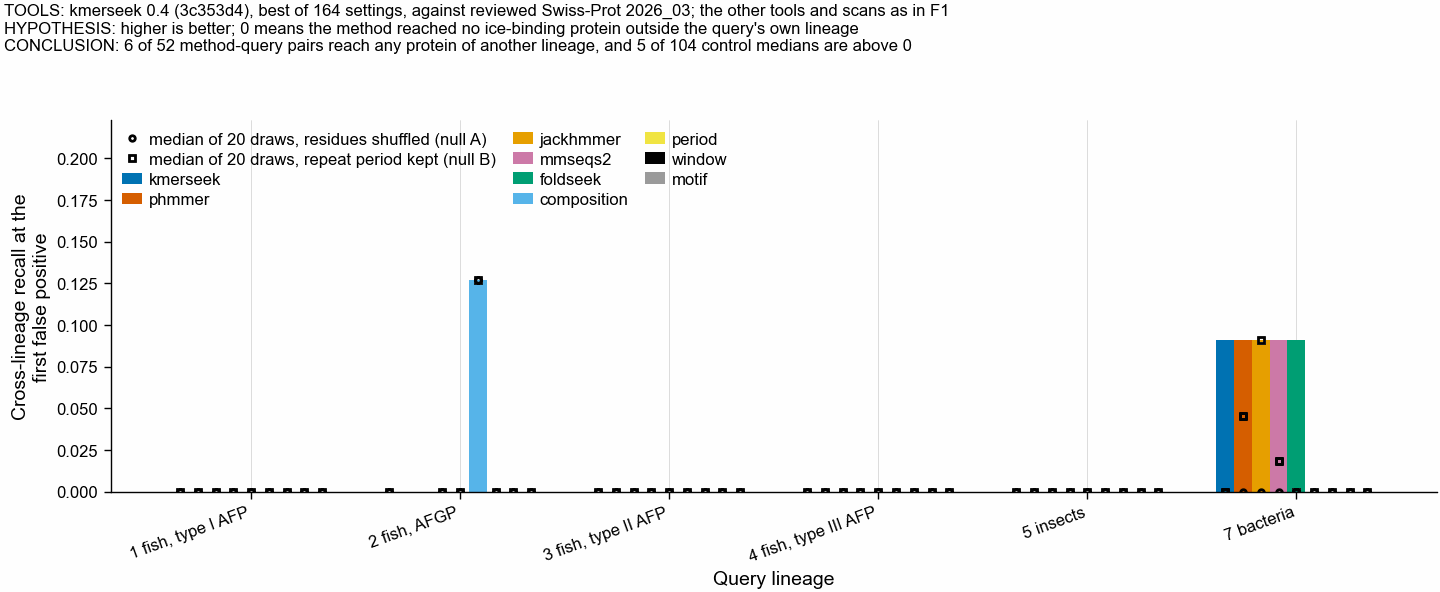

In [5]:
nulls = metrics.filter(pl.col("kind") != "real").with_columns(
    recall_at_real=pl.col("n_found_at_real_threshold") / pl.col("n_cross_truth")
)
best_per = (
    real.sort("recall", descending=True)
    .group_by("query_lineage", "method")
    .head(1)
    .select(
        "query_lineage", "method", "setting_label", "recall", "n_found", "n_cross_truth"
    )
)
null_med = (
    nulls.join(
        best_per.select("query_lineage", "method", "setting_label"),
        on=["query_lineage", "method", "setting_label"],
    )
    .group_by("query_lineage", "method", "kind")
    .agg(pl.col("recall_at_real").median().alias("median_recall"))
)
print(best_per.sort("query_lineage", "recall", descending=[False, True]))
print()
print(
    null_med.pivot(
        values="median_recall", index=["query_lineage", "method"], on="kind"
    ).sort("query_lineage")
)

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 70)
width = 0.085
for k, method in enumerate(METHOD_ORDER):
    xs, ys = [], []
    for i, lineage in enumerate(QUERY_LINEAGES):
        row = best_per.filter(
            (pl.col("query_lineage") == lineage) & (pl.col("method") == method)
        )
        if not row.height:
            continue
        xs.append(i + (k - len(METHOD_ORDER) / 2) * width + width / 2)
        ys.append(row["recall"][0])
    ax.bar(xs, ys, width=width, color=METHOD_COLOUR[method], label=method)
    for kind, marker in [("nullA", "o"), ("nullB", "s")]:
        mx, my = [], []
        for x, lineage in zip(
            xs,
            [
                l
                for l in QUERY_LINEAGES
                if (
                    best_per.filter(
                        (pl.col("query_lineage") == l) & (pl.col("method") == method)
                    ).height
                )
            ],
        ):
            row = null_med.filter(
                (pl.col("query_lineage") == lineage)
                & (pl.col("method") == method)
                & (pl.col("kind") == kind)
            )
            if row.height:
                mx.append(x)
                my.append(row["median_recall"][0])
        ax.plot(
            mx,
            my,
            marker,
            color="black",
            markersize=2,
            markerfacecolor="none",
            linestyle="none",
            label=(
                {
                    "nullA": "median of 20 draws, residues shuffled (null A)",
                    "nullB": "median of 20 draws, repeat period kept (null B)",
                }[kind]
                if k == 0
                else None
            ),
        )
ax.set_ylim(0, max(0.02, float(best_per["recall"].max()) * 1.75))
ax.set_xticks(range(len(QUERY_LINEAGES)))
ax.set_xticklabels(QUERY_LINEAGES, rotation=20, ha="right")
ax.set_ylabel("Cross-lineage recall at the\nfirst false positive")
ax.set_xlabel("Query lineage")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
legend_in_axes(ax, ncol=3, loc="upper left")
n_above = int((best_per["recall"] > 0).sum())
n_pairs = best_per.height
header(
    fig,
    "kmerseek 0.4 (3c353d4), best of 164 settings, against reviewed Swiss-Prot 2026_03; "
    "the other tools and scans as in F1",
    "higher is better; 0 means the method reached no ice-binding protein outside the "
    "query's own lineage",
    f"{n_above} of {n_pairs} method-query pairs reach any protein of another lineage, and "
    f"{int((null_med['median_recall'] > 0).sum())} of {null_med.height} control medians "
    "are above 0",
)
pf.save(fig, FIGURES / "295_F2_cross_lineage_recall_swissprot_2026_03")

## 5. F3: the residues of the only cross-lineage hits kmerseek makes

Every cross-lineage hit kmerseek makes above its threshold is the bacterial ice-binding
protein H7FWB6 against the Arctic yeast protein C7F6X3. Both carry UniProt's "Ice-binding
protein family" annotation, so this pair is related by ancestry, which is why phmmer,
jackhmmer, MMseqs2 and Foldseek find it as well.

The block below is the aligned residues as kmerseek reports them: no gaps, coordinates
0-based and end-exclusive, with the hydrophobic-polar string of each sequence underneath
and a bar where the two agree.

53 residue blocks and 2 chained regions with no residue block
distinct pairs: ['H7FWB6__real vs B8XC03', 'H7FWB6__real vs B8XC03 (8 other)', 'H7FWB6__real vs B8XC04', 'H7FWB6__real vs B8XC04 (8 other)', 'H7FWB6__real vs C7F6X3 (8 other)', 'H7FWB6__real vs Q76CE6 (8 other)', 'H7FWB6__real vs Q76CE8 (8 other)']

shown: hsdm17.k6.s1.lcfalse.extend-c0.18
region_evalue 3.47, region_ka_bits 33.76, 30 of 49 identical, longest matching h/p run 10

query     131 LTTAVGDMQIAYDNAAGRLNPDFLNLGAGTIGGKTLTPGLYKWTSTLNI 180
              ||||| ||| |   | ||  ||| ||| |  ||  |||||||||     
target    144 LTTAVSDMQTAFNDATGRVTPDFTNLGGGELGGLVLTPGLYKWTGAVSV 193

query  h/p    hpphhpphphhhpphhpphphphhphphpphpppphphphhphppphph
              ||||||||| ||||| ||||||| ||| |||||  |||||||||| |||
target h/p    hpphhpphpphhpphppphphphpphpppphpphhhphphhphpphhph


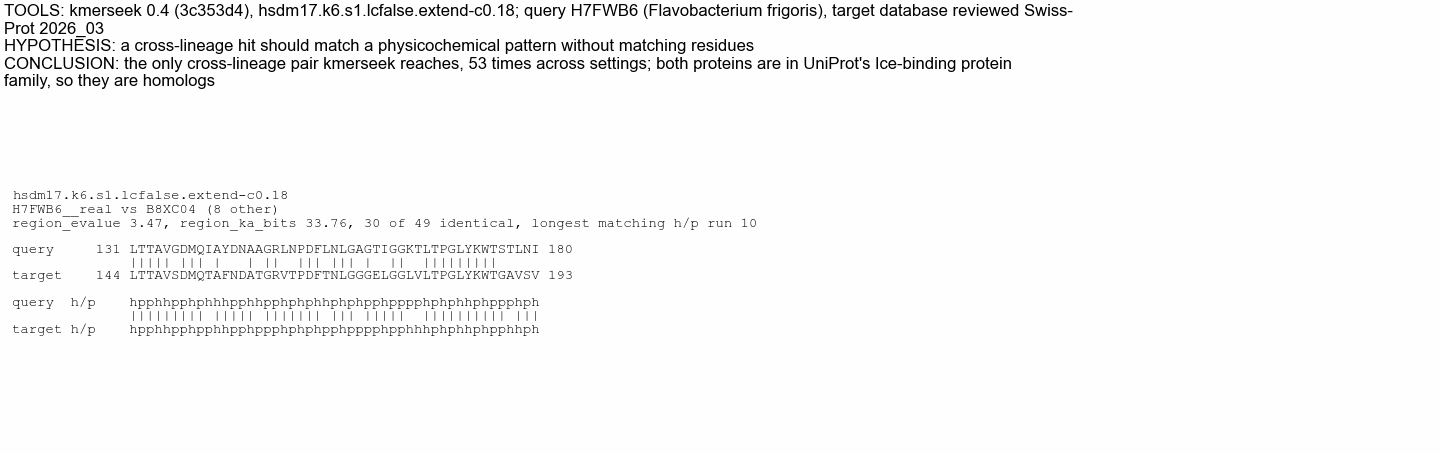

In [6]:
blocks, chained = [], []
for chunk in hits_md.split("\n## ")[1:]:
    head, _, body = chunk.partition("\n")
    setting, _, pair = head.partition(": ")
    stats = next((ln for ln in body.splitlines() if ln.strip()), "")
    m = re.search(r"```\n(.*?)```", body, re.S)
    if m:
        blocks.append(
            {
                "setting": setting,
                "pair": pair,
                "stats": stats,
                "text": m.group(1).rstrip("\n"),
            }
        )
    else:
        # A chained region: the query and target spans differ in length, so there are no
        # residues to line up. score.py writes the note instead of a block.
        chained.append({"setting": setting, "pair": pair, "stats": stats})
print(
    f"{len(blocks)} residue blocks and {len(chained)} chained regions with no residue block"
)
print(f"distinct pairs: {sorted({b['pair'] for b in blocks + chained})}")
chosen = next(
    (b for b in blocks if b["setting"] == verdict["chosen_setting"]), blocks[0]
)
print(f"\nshown: {chosen['setting']}\n{chosen['stats']}\n")
print(chosen["text"])

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 48)
ax.axis("off")
ax.text(
    0.0,
    1.0,
    f"{chosen['setting']}\n{chosen['pair']}\n{chosen['stats']}\n\n{chosen['text']}",
    family="monospace",
    fontsize=5,
    va="top",
    ha="left",
    transform=ax.transAxes,
)
header(
    fig,
    f"kmerseek 0.4 (3c353d4), {chosen['setting']}; query H7FWB6 (Flavobacterium frigoris), "
    "target database reviewed Swiss-Prot 2026_03",
    "a cross-lineage hit should match a physicochemical pattern without matching residues",
    f"the only cross-lineage pair kmerseek reaches, {len(blocks)} times across settings; both "
    "proteins are in UniProt's Ice-binding protein family, so they are homologs",
)
pf.save(fig, FIGURES / "295_F3_kmerseek_cross_lineage_hit_residues_swissprot_2026_03")

## 6. SF2: what the controls reach, draw by draw

Each point is one of the 20 draws, counted at the real query's score cutoff, for the
kmerseek setting the rule chose. The real query's count is the cross. With 20 draws a
point cloud is the honest picture; a density curve over 20 values would invent a shape.

shape: (18, 5)
┌────────────────────┬───────┬────────┬─────┬─────────┐
│ query_lineage      ┆ kind  ┆ median ┆ max ┆ n_draws │
│ ---                ┆ ---   ┆ ---    ┆ --- ┆ ---     │
│ str                ┆ str   ┆ f64    ┆ i64 ┆ u32     │
╞════════════════════╪═══════╪════════╪═════╪═════════╡
│ 1 fish, type I AFP ┆ nullA ┆ 0.0    ┆ 0   ┆ 20      │
│ 1 fish, type I AFP ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ 1 fish, type I AFP ┆ real  ┆ 0.0    ┆ 0   ┆ 1       │
│ 2 fish, AFGP       ┆ nullA ┆ 0.0    ┆ 0   ┆ 20      │
│ 2 fish, AFGP       ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ …                  ┆ …     ┆ …      ┆ …   ┆ …       │
│ 5 insects          ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ 5 insects          ┆ real  ┆ 0.0    ┆ 0   ┆ 1       │
│ 7 bacteria         ┆ nullA ┆ 0.0    ┆ 0   ┆ 20      │
│ 7 bacteria         ┆ nullB ┆ 0.0    ┆ 0   ┆ 20      │
│ 7 bacteria         ┆ real  ┆ 5.0    ┆ 5   ┆ 1       │
└────────────────────┴───────┴────────┴─────┴─────────┘


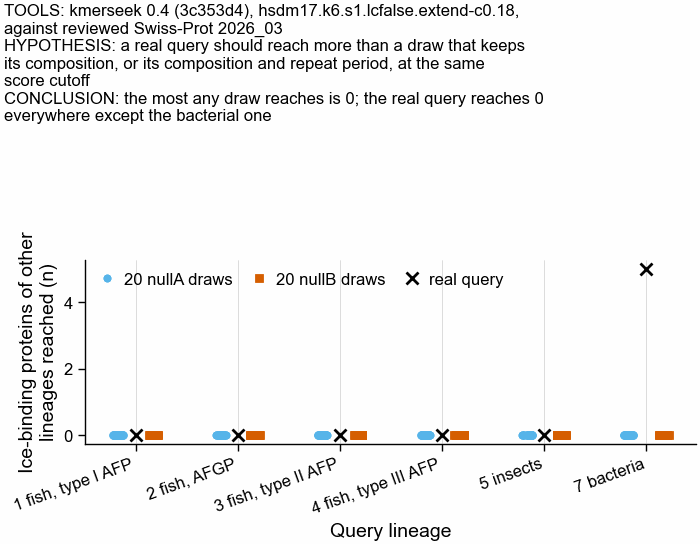

In [7]:
chosen_setting = verdict["chosen_setting"]
sub = metrics.filter(
    (pl.col("method") == "kmerseek") & (pl.col("setting_label") == chosen_setting)
)
print(
    sub.group_by("query_lineage", "kind")
    .agg(
        pl.col("n_found_at_real_threshold").median().alias("median"),
        pl.col("n_found_at_real_threshold").max().alias("max"),
        pl.len().alias("n_draws"),
    )
    .sort("query_lineage", "kind")
)

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 55)
rng = np.random.default_rng(0)
for kind, colour, marker in [
    ("nullA", pf.OKABE_ITO["sky_blue"], "o"),
    ("nullB", pf.OKABE_ITO["vermillion"], "s"),
]:
    for i, lineage in enumerate(QUERY_LINEAGES):
        v = sub.filter((pl.col("kind") == kind) & (pl.col("query_lineage") == lineage))[
            "n_found_at_real_threshold"
        ].to_numpy()
        if not len(v):
            continue
        dx = -0.17 if kind == "nullA" else 0.17
        ax.plot(
            i + dx + rng.uniform(-0.05, 0.05, len(v)),
            v,
            marker,
            color=colour,
            markersize=2,
            linestyle="none",
            label=f"20 {kind} draws" if i == 0 else None,
        )
for i, lineage in enumerate(QUERY_LINEAGES):
    v = sub.filter((pl.col("kind") == "real") & (pl.col("query_lineage") == lineage))[
        "n_found"
    ]
    if v.len():
        ax.plot(
            i,
            v[0],
            "x",
            color="black",
            markersize=4,
            label="real query" if i == 0 else None,
        )
ax.set_xticks(range(len(QUERY_LINEAGES)))
ax.set_xticklabels(QUERY_LINEAGES, rotation=20, ha="right")
ax.set_ylabel("Ice-binding proteins of other\nlineages reached (n)")
ax.set_xlabel("Query lineage")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
legend_in_axes(ax, ncol=3, loc="upper left")
header(
    fig,
    f"kmerseek 0.4 (3c353d4), {chosen_setting}, against reviewed Swiss-Prot 2026_03",
    "a real query should reach more than a draw that keeps its composition, or its "
    "composition and repeat period, at the same score cutoff",
    f"the most any draw reaches is {int(sub.filter(pl.col('kind') != 'real')['n_found_at_real_threshold'].max())}; "
    "the real query reaches 0 everywhere except the bacterial one",
)
pf.save(fig, FIGURES / "295_SF2_null_draws_swissprot_2026_03")

## 7. The decision

The three numbers of the rule, for each held-out lineage, straight from
`verdict.json`.

shape: (2, 9)
┌────────────┬────────────┬────────────┬────────────┬───┬────────────┬───────────┬────────┬────────┐
│ held-out   ┆ kmerseek   ┆ best compo ┆ margin     ┆ … ┆ which      ┆ real      ┆ null B ┆ passes │
│ lineage    ┆ recall     ┆ sition or  ┆ (rule      ┆   ┆ ---        ┆ reached   ┆ median ┆ ---    │
│ ---        ┆ ---        ┆ period     ┆ needs >=   ┆   ┆ str        ┆ ---       ┆ ---    ┆ bool   │
│ str        ┆ f64        ┆ ---        ┆ 0.10)      ┆   ┆            ┆ f64       ┆ f64    ┆        │
│            ┆            ┆ f64        ┆ ---        ┆   ┆            ┆           ┆        ┆        │
│            ┆            ┆            ┆ f64        ┆   ┆            ┆           ┆        ┆        │
╞════════════╪════════════╪════════════╪════════════╪═══╪════════════╪═══════════╪════════╪════════╡
│ 2 fish,    ┆ 0.0        ┆ 0.127273   ┆ -0.127273  ┆ … ┆ compositio ┆ 0.0       ┆ 0.0    ┆ false  │
│ AFGP       ┆            ┆            ┆            ┆   ┆ n_wass14   ┆       

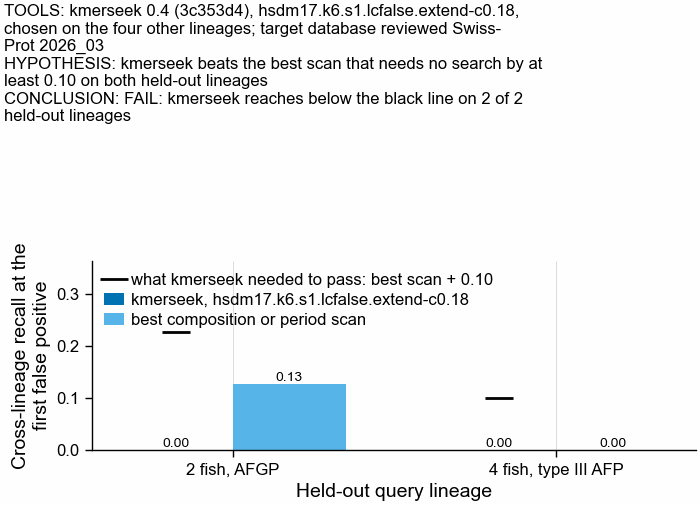

In [8]:
rows = []
for lineage, d in verdict["per_held_out_lineage"].items():
    rows.append(
        {
            "held-out lineage": lineage,
            "kmerseek recall": d["kmerseek_recall"],
            "best composition or period": d["best_composition_or_period_recall"],
            "margin (rule needs >= 0.10)": d["margin_over_composition_and_period"],
            "best of every no-search method": d["best_no_search_recall"],
            "which": d["best_no_search_list"],
            "real reached": d["real_n_found"],
            "null B median": d["null_b_median_n_found_at_real_threshold"],
            "passes": d["passes_margin_rule"] and d["passes_null_b_rule"],
        }
    )
decision = pl.DataFrame(rows)
print(decision)
print()
print(f"chosen setting:            {verdict['chosen_setting']}")
print(f"chosen on:                 {', '.join(verdict['chosen_on'])}")
print(f"its in-sample mean recall: {verdict['chosen_mean_recall_in_sample']:.4f}")
print(f"held-out lineages passing: {len(verdict['held_out_lineages_passing'])} of 2")
print()
print(f"VERDICT: {verdict['verdict']}")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 50)
x = np.arange(decision.height)
w = 0.35
ax.bar(
    x - w / 2,
    decision["kmerseek recall"],
    width=w,
    color=METHOD_COLOUR["kmerseek"],
    label=f"kmerseek, {verdict['chosen_setting']}",
)
ax.bar(
    x + w / 2,
    decision["best composition or period"],
    width=w,
    color=METHOD_COLOUR["composition"],
    label="best composition or period scan",
)
ax.plot(
    x - w / 2,
    decision["best composition or period"] + 0.10,
    "_",
    color="black",
    markersize=10,
    markeredgewidth=1,
    linestyle="none",
    label="what kmerseek needed to pass: best scan + 0.10",
)
for xi, (k_val, s_val) in enumerate(
    zip(decision["kmerseek recall"], decision["best composition or period"])
):
    for dx, v in [(-w / 2, k_val), (w / 2, s_val)]:
        ax.text(xi + dx, v, f"{v:.2f}", ha="center", va="bottom", fontsize=5)
ax.set_xticks(x)
ax.set_xticklabels(decision["held-out lineage"])
ax.set_ylim(0, float((decision["best composition or period"] + 0.10).max()) * 1.6)
ax.set_ylabel("Cross-lineage recall at the\nfirst false positive")
ax.set_xlabel("Held-out query lineage")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
legend_in_axes(ax, loc="upper left")
header(
    fig,
    f"kmerseek 0.4 (3c353d4), {verdict['chosen_setting']}, chosen on the four other lineages; "
    "target database reviewed Swiss-Prot 2026_03",
    "kmerseek beats the best scan that needs no search by at least 0.10 on both held-out lineages",
    f"{verdict['verdict']}: kmerseek reaches below the black line on "
    f"{decision.height - len(verdict['held_out_lineages_passing'])} of {decision.height} held-out lineages",
)
pf.save(fig, FIGURES / "295_SF4_decision_swissprot_2026_03")

## 8. Three more patterns that evolved more than once: truth sets only, no search yet

The same test can be asked of any protein pattern that arose separately in unrelated
lineages. Three more were built with `scripts/convergence_classes_truth.py`, from the
UniProt REST API, release 2026_03:

* **Adhesive (B).** Underwater glue rich in tyrosine and lysine, where the tyrosine
  becomes DOPA after translation. Mussels and sandcastle worms arrived at it separately.
  Barnacle cement does the same job with a different chemistry and is the control.
* **Shell matrix (C).** Aspartate- and glutamate-rich, low-complexity proteins in
  mollusc shells, coral skeletons, sea-urchin tests and vertebrate bone.
* **Silk (D).** Long repeats of short glycine- and alanine-rich units. Spiders and the
  moths-plus-caddisflies clade are two separate origins. Bee, ant and hornet silks are
  coiled coils, a different pattern, and are the control.

An entry counts as a cross-lineage target only if it is reviewed (Swiss-Prot), sits in a
lineage that carries the pattern, and, for shell and silk, carries the pattern itself by
its composition or repeats. A class is a benchmark only if it has at least 20 such entries
in at least 2 lineages; otherwise it can only be a case study. The searches have not been
run for any of the three.

shape: (3, 5)
┌──────────┬─────────┬─────────────────┬───────────────────────────┬────────────┐
│ class    ┆ entries ┆ counted targets ┆ pattern lineages with one ┆ result     │
│ ---      ┆ ---     ┆ ---             ┆ ---                       ┆ ---        │
│ str      ┆ i64     ┆ i64             ┆ i64                       ┆ str        │
╞══════════╪═════════╪═════════════════╪═══════════════════════════╪════════════╡
│ adhesive ┆ 10      ┆ 6               ┆ 1                         ┆ case study │
│ shell    ┆ 626     ┆ 75              ┆ 4                         ┆ benchmark  │
│ silk     ┆ 65      ┆ 3               ┆ 2                         ┆ case study │
└──────────┴─────────┴─────────────────┴───────────────────────────┴────────────┘

shape: (12, 4)
┌─────────────────────────────────┬─────────┬─────────────┬──────────┐
│ lineage                         ┆ counted ┆ not_counted ┆ class    │
│ ---                             ┆ ---     ┆ ---         ┆ ---      │
│ str              

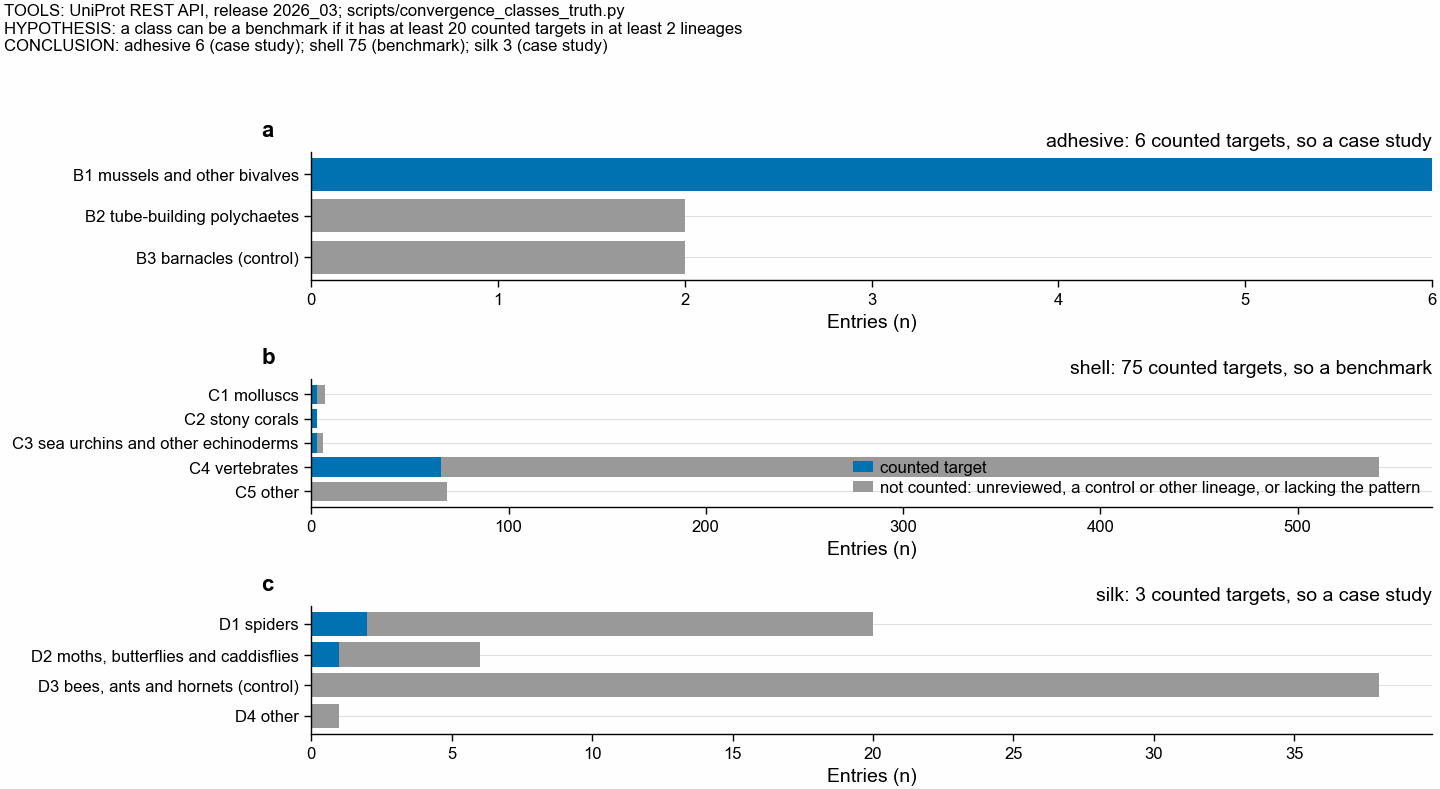

In [9]:
CLASS_PATTERN_LINEAGES = {
    "adhesive": ["B1 mussels and other bivalves", "B2 tube-building polychaetes"],
    "shell": [
        "C1 molluscs",
        "C2 stony corals",
        "C3 sea urchins and other echinoderms",
        "C4 vertebrates",
    ],
    "silk": ["D1 spiders", "D2 moths, butterflies and caddisflies"],
}
MIN_CROSS_TARGETS, MIN_QUERY_LINEAGES = 20, 2

gate_rows, lineage_rows = [], []
for cls, pattern in CLASS_PATTERN_LINEAGES.items():
    t = pl.read_csv(
        f"../data/convergence_{cls}/truth_set.tsv",
        separator="\t",
        infer_schema_length=0,
    )
    counted = (pl.col("tier") == "Swiss-Prot") & pl.col("lineage").is_in(pattern)
    if cls == "shell":
        counted = counted & (pl.col("kind") == "acidic or low complexity")
    if cls == "silk":
        counted = counted & (pl.col("kind") != "neither")
    t = t.with_columns(counted=counted)
    usable = t.filter("counted")
    n_lineages = usable["lineage"].n_unique()
    gate_rows.append(
        {
            "class": cls,
            "entries": t.height,
            "counted targets": usable.height,
            "pattern lineages with one": n_lineages,
            "result": (
                "benchmark"
                if usable.height >= MIN_CROSS_TARGETS
                and n_lineages >= MIN_QUERY_LINEAGES
                else "case study"
            ),
        }
    )
    lineage_rows.append(
        t.group_by("lineage")
        .agg(
            pl.col("counted").sum().alias("counted"),
            (~pl.col("counted")).sum().alias("not_counted"),
        )
        .with_columns(pl.lit(cls).alias("class"))
    )
gate = pl.DataFrame(gate_rows)
per_class_lineage = pl.concat(lineage_rows).sort("class", "lineage")
print(gate)
print()
print(per_class_lineage)

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=3)
for ax, cls in zip(axs, CLASS_PATTERN_LINEAGES):
    sub = per_class_lineage.filter(pl.col("class") == cls)
    y = np.arange(sub.height)
    ax.barh(y, sub["counted"], color=pf.OKABE_ITO["blue"], label="counted target")
    ax.barh(
        y,
        sub["not_counted"],
        left=sub["counted"],
        color=pf.GREY,
        label="not counted: unreviewed, a control or other lineage, or lacking the pattern",
    )
    ax.set_yticks(y)
    ax.set_yticklabels(sub["lineage"])
    ax.invert_yaxis()
    ax.set_xlabel("Entries (n)")
    g = gate.filter(pl.col("class") == cls).row(0, named=True)
    ax.set_title(
        f"{cls}: {g['counted targets']} counted targets, so a {g['result']}",
        loc="right",
        pad=2,
    )
    ax.grid(axis="y", which="major")
    ax.set_axisbelow(True)
for ax, letter in zip(axs, "abc"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[1], loc="lower right")
header(
    fig,
    "UniProt REST API, release 2026_03; scripts/convergence_classes_truth.py",
    f"a class can be a benchmark if it has at least {MIN_CROSS_TARGETS} counted targets in "
    f"at least {MIN_QUERY_LINEAGES} lineages",
    "; ".join(
        f"{r['class']} {r['counted targets']} ({r['result']})" for r in gate_rows
    ),
)
pf.save(fig, FIGURES / "295_SF5_other_classes_truth_sets_uniprot_2026_03")

## 9. Could any k-mer setting have reached them? The ceiling from shared k-mers

kmerseek reports a target only if it shares at least 2 distinct k-mers with the query in
the reduced alphabet (`--min-shared-kmers 2`). A protein below that bar is never in the
list, whatever its score would have been. So counting shared k-mers directly gives the
most any setting at that alphabet and k could reach, with no index and no search.

`scripts/convergence_kmer_reach_ceiling.py` counts, for each real query, alphabet and k
from 3 to 40: the ice-binding proteins of other lineages that share at least 2 k-mers
with the query, and the share of 5_000 random Swiss-Prot entries that do. It covers the
eight alphabets whose groups are written out in kmerseek's source as two or six groups:
the 20 amino acids, Dayhoff, and the seven hydrophobic-polar alphabets.

A point above the diagonal reaches more ice-binding proteins than random proteins, in
proportion. That is the only place a setting could find them without finding everything.

Most ice-binding proteins of other lineages reachable while at most 1% of random
Swiss-Prot entries are, per query and alphabet family:
shape: (18, 7)
┌───────────────┬──────────────┬──────────────┬───────┬──────────────┬──────────────┬──────────────┐
│ query_lineage ┆ family       ┆ alphabet     ┆ ksize ┆ n_cross_reac ┆ n_cross_trut ┆ frac_backgro │
│ ---           ┆ ---          ┆ ---          ┆ ---   ┆ hable        ┆ h            ┆ und_reachabl │
│ str           ┆ str          ┆ str          ┆ i64   ┆ ---          ┆ ---          ┆ e            │
│               ┆              ┆              ┆       ┆ i64          ┆ i64          ┆ ---          │
│               ┆              ┆              ┆       ┆              ┆              ┆ f64          │
╞═══════════════╪══════════════╪══════════════╪═══════╪══════════════╪══════════════╪══════════════╡
│ 1 fish, type  ┆ dayhoff6     ┆ dayhoff6     ┆ 15    ┆ 0            ┆ 47           ┆ 0.0094       │
│ I AFP         ┆              ┆         

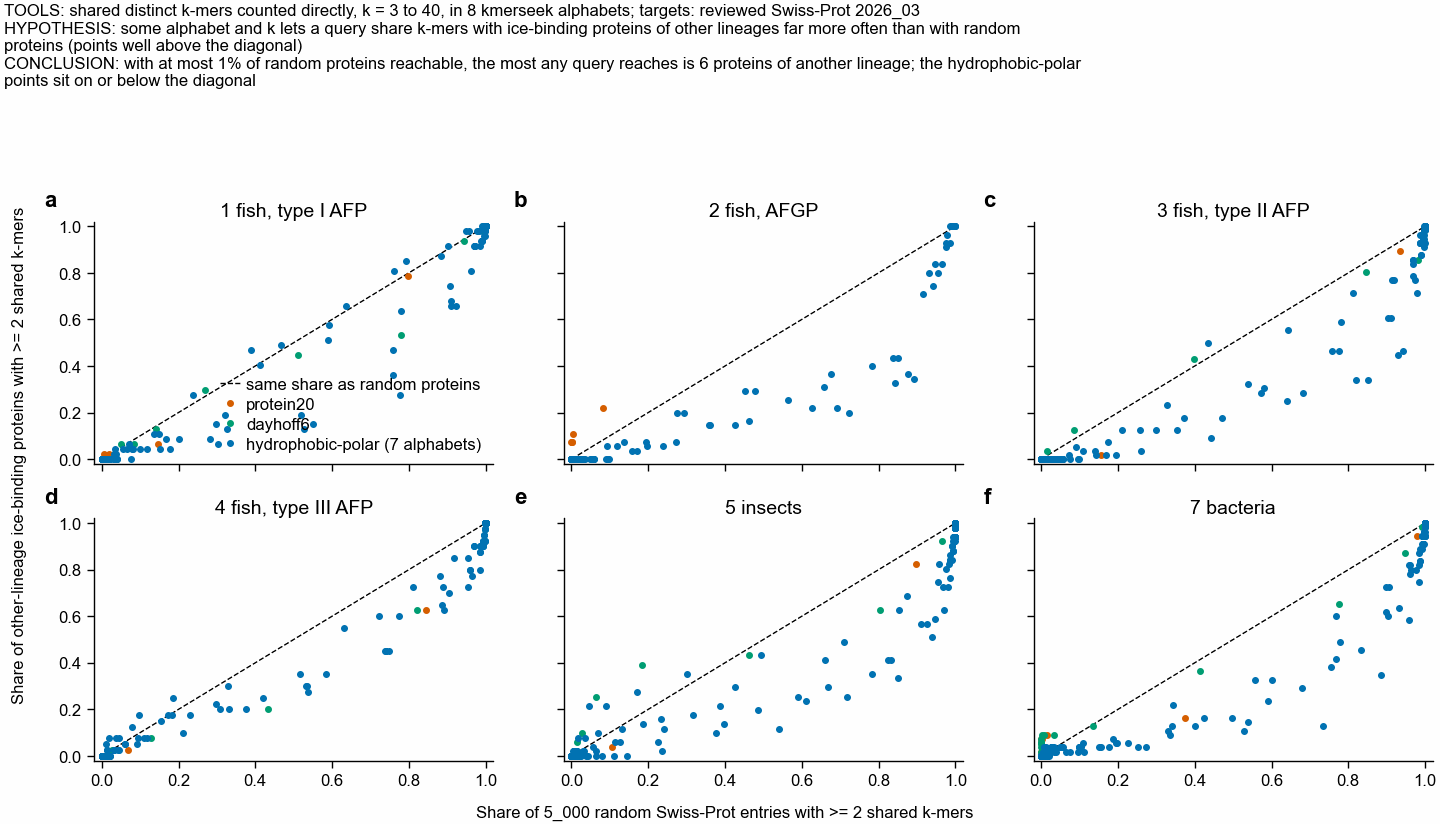

In [10]:
ceiling = pl.read_csv(TRUTH_DIR / "kmer_reach_ceiling.tsv", separator="\t")
ceiling = ceiling.with_columns(
    family=pl.when(pl.col("alphabet").str.starts_with("hp_"))
    .then(pl.lit("hydrophobic-polar (7 alphabets)"))
    .otherwise(pl.col("alphabet"))
)
best = (
    ceiling.filter(pl.col("frac_background_reachable") <= 0.01)
    .sort("n_cross_reachable", descending=True)
    .group_by("query_lineage", "family")
    .head(1)
    .select(
        "query_lineage",
        "family",
        "alphabet",
        "ksize",
        "n_cross_reachable",
        "n_cross_truth",
        "frac_background_reachable",
    )
    .sort("query_lineage", "family")
)
print(
    "Most ice-binding proteins of other lineages reachable while at most 1% of random"
)
print("Swiss-Prot entries are, per query and alphabet family:")
print(best)

FAMILY_COLOUR = {
    "protein20": pf.OKABE_ITO["vermillion"],
    "dayhoff6": pf.OKABE_ITO["bluish_green"],
    "hydrophobic-polar (7 alphabets)": pf.OKABE_ITO["blue"],
}
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=3, sharex=True, sharey=True)
for ax, lineage in zip(axs.ravel(), QUERY_LINEAGES):
    sub = ceiling.filter(pl.col("query_lineage") == lineage)
    ax.plot(
        [0, 1],
        [0, 1],
        color="black",
        linewidth=0.5,
        linestyle="--",
        label="same share as random proteins",
    )
    for fam, colour in FAMILY_COLOUR.items():
        f = sub.filter(pl.col("family") == fam)
        ax.plot(
            f["frac_background_reachable"],
            f["frac_cross_reachable"],
            "o",
            color=colour,
            markersize=1.5,
            linestyle="none",
            label=fam,
        )
    ax.set_title(lineage, pad=2)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
# One label per axis for the whole grid: per-panel labels in two rows overlapped.
fig.supxlabel(
    "Share of 5_000 random Swiss-Prot entries with >= 2 shared k-mers", fontsize=6
)
fig.supylabel(
    "Share of other-lineage ice-binding proteins with >= 2 shared k-mers", fontsize=6
)
for ax, letter in zip(axs.ravel(), "abcdef"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[0, 0], loc="lower right")
header(
    fig,
    "shared distinct k-mers counted directly, k = 3 to 40, in 8 kmerseek alphabets; "
    "targets: reviewed Swiss-Prot 2026_03",
    "some alphabet and k lets a query share k-mers with ice-binding proteins of other "
    "lineages far more often than with random proteins (points well above the diagonal)",
    f"with at most 1% of random proteins reachable, the most any query reaches is "
    f"{int(best['n_cross_reachable'].max())} proteins of another lineage; the "
    "hydrophobic-polar points sit on or below the diagonal",
)
pf.save(fig, FIGURES / "295_SF6_shared_kmer_ceiling_swissprot_2026_03")

## 10. The same ceiling for the shell-matrix class: worth a search?

Section 8 found the shell-matrix class the only one large enough to be a benchmark. Before
running its searches, the same count as section 9 asks whether any k-mer setting could
reach its proteins across lineages better than chance. One query per pattern lineage,
picked by the class script's rule (most experimental evidence, ties to the longer entry),
against the 75 counted targets and 5_000 random Swiss-Prot entries
(`scripts/convergence_kmer_reach_ceiling.py --class shell`).

The class was defined by composition: a counted target has an Asp+Glu share of at least
0.20 or a low-complexity fraction of at least 0.30. So composition alone is the bar any
search has to beat, and it is drawn as a star at the share of random proteins that pass
the same rule.

shape: (3, 4)
┌────────────────────────────────┬──────────────┬────────┬───────────┐
│ rule                           ┆ n_background ┆ n_pass ┆ frac_pass │
│ ---                            ┆ ---          ┆ ---    ┆ ---       │
│ str                            ┆ i64          ┆ i64    ┆ f64       │
╞════════════════════════════════╪══════════════╪════════╪═══════════╡
│ Asp+Glu share >= 0.2           ┆ 5000         ┆ 97     ┆ 0.0194    │
│ low-complexity fraction >= 0.3 ┆ 5000         ┆ 137    ┆ 0.0274    │
│ either (the class C rule)      ┆ 5000         ┆ 226    ┆ 0.0452    │
└────────────────────────────────┴──────────────┴────────┴───────────┘

counted targets per lineage:
shape: (4, 2)
┌─────────────────────────────────┬─────┐
│ lineage                         ┆ len │
│ ---                             ┆ --- │
│ str                             ┆ u32 │
╞═════════════════════════════════╪═════╡
│ C1 molluscs                     ┆ 3   │
│ C2 stony corals                 ┆ 3   │
│ C3 sea 

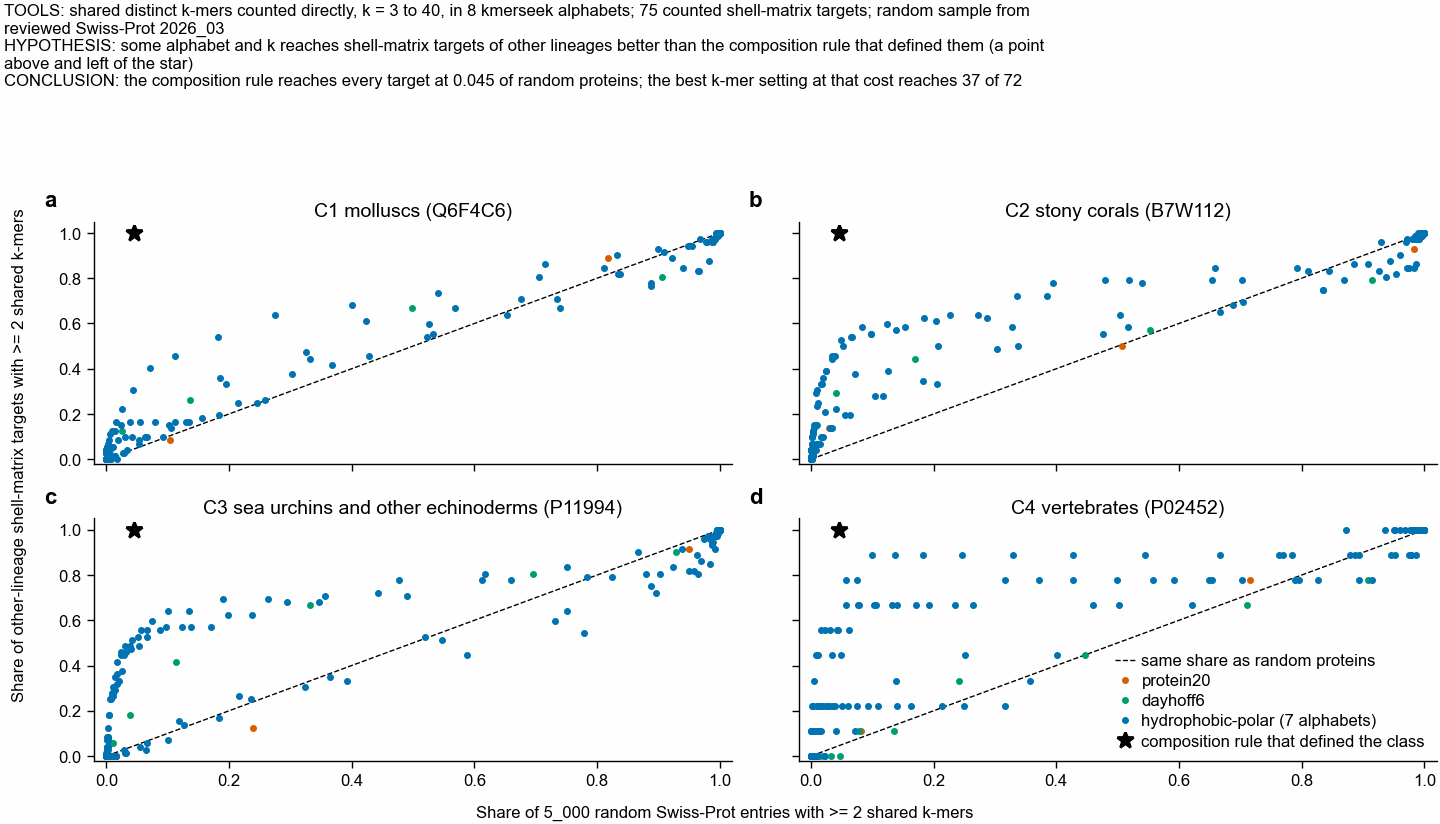

In [11]:
shell_dir = Path("../data/convergence_shell")
shell_ceiling = pl.read_csv(
    shell_dir / "kmer_reach_ceiling.tsv", separator="\t"
).with_columns(
    family=pl.when(pl.col("alphabet").str.starts_with("hp_"))
    .then(pl.lit("hydrophobic-polar (7 alphabets)"))
    .otherwise(pl.col("alphabet"))
)
comp_rule = pl.read_csv(shell_dir / "composition_rule_background.tsv", separator="\t")
rule_frac = float(
    comp_rule.filter(pl.col("rule").str.starts_with("either"))["frac_pass"][0]
)
print(comp_rule)
print()

shell_truth = pl.read_csv(
    shell_dir / "truth_set.tsv", separator="\t", infer_schema_length=0
)
counted = shell_truth.filter(
    (pl.col("tier") == "Swiss-Prot")
    & pl.col("lineage").is_in(CLASS_PATTERN_LINEAGES["shell"])
    & (pl.col("kind") == "acidic or low complexity")
)
print("counted targets per lineage:")
print(counted.group_by("lineage").len().sort("lineage"))
print()
shell_best = (
    shell_ceiling.filter(pl.col("frac_background_reachable") <= rule_frac)
    .sort("n_cross_reachable", descending=True)
    .group_by("query_lineage")
    .head(1)
    .select(
        "query",
        "query_lineage",
        "alphabet",
        "ksize",
        "n_cross_reachable",
        "n_cross_truth",
        "frac_background_reachable",
    )
    .sort("query_lineage")
)
print(
    f"Most counted targets of other lineages reachable by shared k-mers, while no more"
)
print(
    f"random proteins are reachable than pass the composition rule ({rule_frac:.4f}):"
)
print(shell_best)

SHELL_LINEAGES = sorted(shell_ceiling["query_lineage"].unique())
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, nrows=2, ncols=2, sharex=True, sharey=True)
for ax, lineage in zip(axs.ravel(), SHELL_LINEAGES):
    sub = shell_ceiling.filter(pl.col("query_lineage") == lineage)
    ax.plot(
        [0, 1],
        [0, 1],
        color="black",
        linewidth=0.5,
        linestyle="--",
        label="same share as random proteins",
    )
    for fam, colour in FAMILY_COLOUR.items():
        f = sub.filter(pl.col("family") == fam)
        ax.plot(
            f["frac_background_reachable"],
            f["frac_cross_reachable"],
            "o",
            color=colour,
            markersize=1.5,
            linestyle="none",
            label=fam,
        )
    ax.plot(
        [rule_frac],
        [1.0],
        "*",
        color="black",
        markersize=6,
        linestyle="none",
        label="composition rule that defined the class",
    )
    ax.set_title(f"{lineage} ({sub['query'][0]})", pad=2)
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
fig.supxlabel(
    "Share of 5_000 random Swiss-Prot entries with >= 2 shared k-mers", fontsize=6
)
fig.supylabel(
    "Share of other-lineage shell-matrix targets with >= 2 shared k-mers", fontsize=6
)
for ax, letter in zip(axs.ravel(), "abcd"):
    pf.panel_label(ax, letter)
legend_in_axes(axs[1, 1], loc="lower right")
header(
    fig,
    "shared distinct k-mers counted directly, k = 3 to 40, in 8 kmerseek alphabets; "
    "75 counted shell-matrix targets; random sample from reviewed Swiss-Prot 2026_03",
    "some alphabet and k reaches shell-matrix targets of other lineages better than the "
    "composition rule that defined them (a point above and left of the star)",
    f"the composition rule reaches every target at {rule_frac:.3f} of random proteins; the "
    f"best k-mer setting at that cost reaches {int(shell_best['n_cross_reachable'].max())} of "
    f"{int(shell_best.filter(pl.col('n_cross_reachable') == shell_best['n_cross_reachable'].max())['n_cross_truth'][0])}",
)
pf.save(fig, FIGURES / "295_SF7_shell_shared_kmer_ceiling_swissprot_2026_03")

## 11. Case study: mussel foot protein 1 as the query

Section 8 left the adhesive class too small to be a benchmark: 6 mussel entries, 2
sandcastle worm and 2 barnacle. So it is run here as one case study, with the same
pipeline and the same comparison as the ice-binding test.

**The query** is mussel foot protein 1, Q25460 (*Mytilus edulis*, 875 residues): the
glue protein of the byssus threads. Most of it is about 80 copies of a 10-residue repeat
such as AKPSYPPTYK, where the tyrosines become DOPA after translation. The sandcastle
worm *Phragmatopoma californica* glues sand grains with cement proteins that are also
rich in DOPA and lysine but have no known common ancestor with the mussel protein. The
barnacle *Megabalanus rosa* glues with cement proteins of a different chemistry and is
the control.

**What a search should do, if it reads the glue pattern.** Rank the two sandcastle worm
cement proteins above every protein that is not an adhesive, and not the two barnacle
ones. The other mussel proteins come first for any search that reads ancestry: two are
foot protein 1 of other *Mytilus* species, two are foot protein 1 of the green mussel
*Perna viridis*, and one is a different protein, foot protein 2.

**The decision this informs.** Whether the adhesive class is worth a benchmark built from
unreviewed (TrEMBL) entries, which is the only way to get more than 2 worm proteins. This
rule was written on 2026-10-20 after the first look at the scores, so it describes the
result rather than testing it: if any kmerseek setting ranks a worm cement protein above
its first false positive while its 40 null draws do not reach it at the same score, the
class is worth that benchmark; otherwise it is not.

**The data.** Run `adhesive-q25460` of the same pipeline (`make adhesive_q25460`,
2026-10-19, kmerseek 0.4 at 3c353d4, all 230 settings; phmmer, jackhmmer, MMseqs2,
Foldseek and the scans). The target database is Swiss-Prot 2026_03 plus the 3 truth
entries found only in TrEMBL, 575_751 entries. The query also got 20 null A draws
(residues shuffled) and 20 null B draws (the 10-residue repeat kept, its word changed).
Scored with `bin/score.py --no-decide` and `scripts/convergence_adhesive_q25460_detail.py`
(commit 3b810625, Sherlock job 48633802); the tables are in
[data/convergence_adhesive/q25460_run](../data/convergence_adhesive/q25460_run). phmmer
and jackhmmer outputs were recovered chunk by chunk from the run's work folders
(`scripts/convergence_recover_hmmer_chunks.sh`), since the published files kept one chunk
of two (fixed in main.nf, commit 6c7487a0).

**How to read the figure.** Panel a has one row per adhesive protein and one dot per
method: how many proteins outside the adhesive set that method ranked above it, in the
method's best list (for kmerseek, its best of 171 searched settings). 0 means the method
found it before any wrong protein; lower is better. A cross means no list of that method
reported the protein at all. Panel b is every kmerseek setting, so the best one in panel a
can be seen against the rest.

shape: (2, 2)
┌──────────┬───────┐
│ status   ┆ count │
│ ---      ┆ ---   │
│ str      ┆ u32   │
╞══════════╪═══════╡
│ nofit    ┆ 59    │
│ searched ┆ 171   │
└──────────┴───────┘

Lists per method: {'foldseek': 2, 'phmmer': 1, 'window': 10, 'composition': 20, 'jackhmmer': 1, 'period': 2, 'mmseqs2': 1, 'kmerseek': 171}

Each method's best rank for each adhesive protein, Q25460 as the query.
n_wrong_above = proteins outside the adhesive set ranked above it in that list.
shape: (42, 6)
┌───────────────────────────────┬────────┬─────────────┬────────────────────────────────────────────────┬────────┬───────────────┐
│ lineage                       ┆ Entry  ┆ method      ┆ setting_label                                  ┆ rank   ┆ n_wrong_above │
│ ---                           ┆ ---    ┆ ---         ┆ ---                                            ┆ ---    ┆ ---           │
│ str                           ┆ str    ┆ enum        ┆ str                                            ┆ i64    ┆ i

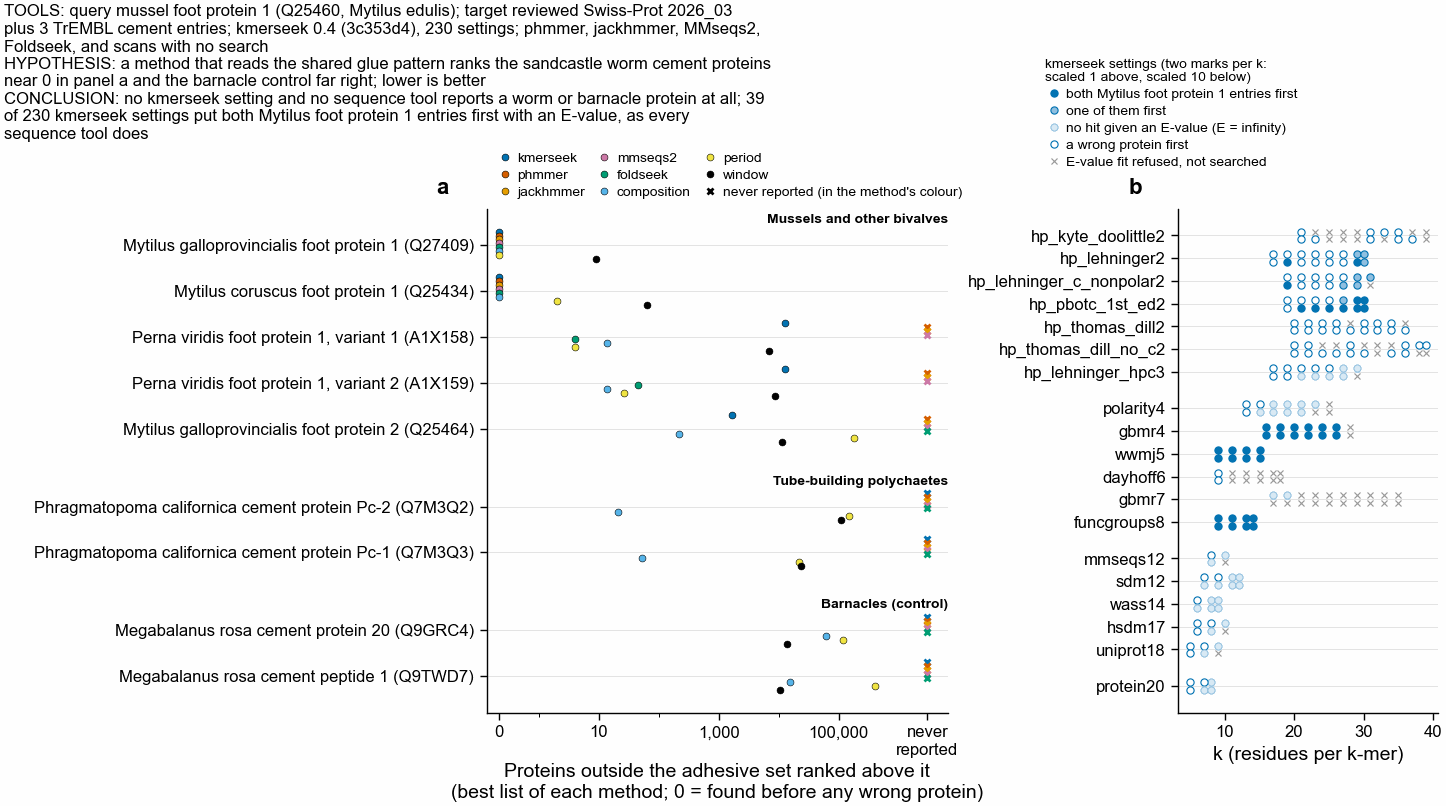

In [12]:
# Print whole tables in this section: they are the evidence for the text.
pl.Config.set_tbl_rows(60)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(200)
ADH_DIR = Path("../data/convergence_adhesive")
Q_RUN = ADH_DIR / "q25460_run"
QUERY_ACC = "Q25460"
adh_truth = pl.read_csv(ADH_DIR / "truth_set.tsv", separator="\t")
settings = pl.read_csv(
    "../nextflow-runs/convergence-afp/assets/kmerseek_settings.tsv", separator="\t"
)
status = pl.read_csv(Q_RUN / "kmerseek_status.tsv", separator="\t")
ranks = pl.read_csv(Q_RUN / "truth_ranks.tsv", separator="\t")
first_fp = pl.read_csv(Q_RUN / "first_false_positive.tsv", separator="\t")
top_hits = pl.read_csv(Q_RUN / "top_hits.tsv", separator="\t")
at_cut = pl.read_csv(Q_RUN / "truth_at_threshold.tsv.gz", separator="\t")

assert status.height == settings.height, "a setting has no status row"
print(status["status"].value_counts().sort("status"))

# Short names a biologist reads: species and protein, by accession.
ADH_LABEL = {
    "Q25434": "Mytilus coruscus foot protein 1",
    "Q27409": "Mytilus galloprovincialis foot protein 1",
    "A1X158": "Perna viridis foot protein 1, variant 1",
    "A1X159": "Perna viridis foot protein 1, variant 2",
    "Q25464": "Mytilus galloprovincialis foot protein 2",
    "Q7M3Q2": "Phragmatopoma californica cement protein Pc-2",
    "Q7M3Q3": "Phragmatopoma californica cement protein Pc-1",
    "Q9GRC4": "Megabalanus rosa cement protein 20",
    "Q9TWD7": "Megabalanus rosa cement peptide 1",
}
MYTILUS_FP1 = ["Q25434", "Q27409"]
others = adh_truth.filter(pl.col("Entry") != QUERY_ACC).select(
    "Entry", "lineage", "Length"
)
assert set(others["Entry"]) == set(ADH_LABEL), "a truth entry has no label"

# Wrong proteins above each truth entry: proteins outside the adhesive set that score at
# least as well in that list (a tie counts against the truth entry, since the order inside
# a tie is arbitrary). Computed in scripts/convergence_adhesive_q25460_detail.py.
wrong_above = ranks.filter(pl.col("target") != QUERY_ACC).rename(
    {"n_wrong_at_or_above": "n_wrong_above"}
)
best = (
    wrong_above.sort("n_wrong_above", "setting_label")
    .group_by("method", "target")
    .head(1)
    .select("method", "target", "setting_label", "rank", "n_wrong_above")
)
n_lists = first_fp.group_by("method").len().rename({"len": "n_lists"})
methods_run = [m for m in METHOD_ORDER if m in n_lists["method"].to_list()]
not_reported = (
    pl.DataFrame({"method": methods_run})
    .join(others.select("Entry"), how="cross")
    .join(
        best.select("method", pl.col("target").alias("Entry")),
        on=["method", "Entry"],
        how="anti",
    )
)
print()
print("Lists per method:", dict(zip(n_lists["method"], n_lists["n_lists"])))
print()
print("Each method's best rank for each adhesive protein, Q25460 as the query.")
print("n_wrong_above = proteins outside the adhesive set ranked above it in that list.")
print(
    others.join(best, left_on="Entry", right_on="target", how="left")
    .with_columns(pl.col("method").cast(pl.Enum(METHOD_ORDER)))
    .sort("lineage", "Entry", "method")
    .select("lineage", "Entry", "method", "setting_label", "rank", "n_wrong_above")
)
print()
print("Never reported by any list of the method:")
print(
    not_reported.group_by("method")
    .agg(pl.col("Entry").sort().str.join(", "))
    .sort("method")
)

# Per kmerseek setting: how many of the two Mytilus foot protein 1 entries score above the
# first wrong protein, and whether the setting gave Q25460's hits any E-value at all.
real_rows = ranks.filter(
    (pl.col("method") == "kmerseek") & pl.col("target").is_in(MYTILUS_FP1)
).with_columns(
    above=(pl.col("cutoff").is_null() | (pl.col("score") > pl.col("cutoff")))
    & (pl.col("score") > float("-inf"))
)
no_evalue = (
    top_hits.filter(pl.col("method") == "kmerseek")
    .group_by("setting_label")
    .agg((pl.col("score") == float("-inf")).all().alias("no_evalue"))
)
per_setting = (
    settings.select("setting_label", "alphabet", "ksize", "scaled")
    .join(status, on="setting_label")
    .join(
        real_rows.group_by("setting_label").agg(
            pl.col("above").sum().alias("n_mytilus")
        ),
        on="setting_label",
        how="left",
    )
    .join(no_evalue, on="setting_label", how="left")
    .with_columns(
        outcome=pl.when(pl.col("status") == "nofit")
        .then(pl.lit("fit refused"))
        .when(pl.col("no_evalue"))
        .then(pl.lit("no E-value"))
        .when(pl.col("n_mytilus") == 2)
        .then(pl.lit("both"))
        .when(pl.col("n_mytilus") == 1)
        .then(pl.lit("one"))
        .otherwise(pl.lit("wrong first"))
    )
)
print()
print("kmerseek settings by what Q25460 reaches before its first wrong protein:")
print(per_setting.group_by("outcome").len().sort("len", descending=True))

ROW_ORDER = [
    (
        "B1 mussels and other bivalves",
        ["Q27409", "Q25434", "A1X158", "A1X159", "Q25464"],
    ),
    ("B2 tube-building polychaetes", ["Q7M3Q2", "Q7M3Q3"]),
    ("B3 barnacles (control)", ["Q9GRC4", "Q9TWD7"]),
]
rows, row_y, group_top, y = [], {}, {}, 0.0
for lineage, entries in ROW_ORDER:
    y += 0.7  # room for the lineage heading
    group_top[lineage] = y - 0.55
    for e in entries:
        row_y[e] = y
        rows.append((y, e))
        y += 1.0
NOT_REPORTED_X = 3e6

# Placed by hand: constrained layout left an empty band between the header and the
# legends, or collapsed the axes when a legend was wide.
fig = plt.figure(figsize=(pf.TWO_COLUMN_MM * pf.MM, 100 * pf.MM))
axs = [fig.add_axes([0.335, 0.10, 0.32, 0.64]), fig.add_axes([0.815, 0.10, 0.18, 0.64])]
ax = axs[0]
for y0, _ in rows:
    ax.axhline(y0, color="#dddddd", linewidth=0.3, zorder=0)
for j, m in enumerate(methods_run):
    dy = (j - (len(methods_run) - 1) / 2) * 0.085
    b = best.filter(pl.col("method") == m)
    ax.plot(
        [max(0, v) for v in b["n_wrong_above"]],
        [row_y[t] + dy for t in b["target"]],
        "o",
        color=METHOD_COLOUR[m],
        markersize=2.5,
        markeredgecolor="black",
        markeredgewidth=0.2,
        linestyle="none",
        label=m,
        zorder=3,
    )
    nr = not_reported.filter(pl.col("method") == m)
    ax.plot(
        [NOT_REPORTED_X] * nr.height,
        [row_y[e] + dy for e in nr["Entry"]],
        "x",
        color=METHOD_COLOUR[m],
        markersize=2.2,
        linestyle="none",
        zorder=3,
    )
ax.set_xscale("symlog", linthresh=1, linscale=0.6)
ax.set_xticks([0, 10, 1_000, 100_000, NOT_REPORTED_X])
ax.set_xticklabels(["0", "10", "1,000", "100,000", "never\nreported"])
ax.set_xticks([1, 100, 10_000], minor=True)
ax.set_xlim(-0.3, NOT_REPORTED_X * 2.2)
ax.set_yticks([r[0] for r in rows])
ax.set_yticklabels([f"{ADH_LABEL[e]} ({e})" for _, e in rows])
ax.invert_yaxis()
ax.set_xlabel(
    "Proteins outside the adhesive set ranked above it\n"
    "(best list of each method; 0 = found before any wrong protein)"
)
for lineage, top in group_top.items():
    ax.text(
        1.0,
        top,
        lineage.split(" ", 1)[1].capitalize(),
        transform=ax.get_yaxis_transform(),
        ha="right",
        va="center",
        fontsize=5,
        fontweight="bold",
    )
handles, labels = ax.get_legend_handles_labels()
handles.append(
    mpl.lines.Line2D(
        [], [], marker="x", color="black", linestyle="none", markersize=2.2
    )
)
labels.append("never reported (in the method's colour)")
ax.legend(
    handles,
    labels,
    loc="lower left",
    bbox_to_anchor=(0.0, 1.0),
    ncol=3,
    frameon=False,
    fontsize=5,
    handletextpad=0.3,
    columnspacing=0.8,
)

ax = axs[1]
ALPHABET_GROUPS = [
    [
        "hp_kyte_doolittle2",
        "hp_lehninger2",
        "hp_lehninger_c_nonpolar2",
        "hp_pbotc_1st_ed2",
        "hp_thomas_dill2",
        "hp_thomas_dill_no_c2",
        "hp_lehninger_hpc3",
    ],
    ["polarity4", "gbmr4", "wwmj5", "dayhoff6", "gbmr7", "funcgroups8"],
    ["mmseqs12", "sdm12", "wass14", "hsdm17", "uniprot18"],
    ["protein20"],
]
present = set(per_setting["alphabet"])
alph_y, yy = {}, 0.0
for g in ALPHABET_GROUPS:
    for a in g:
        if a in present:
            alph_y[a] = yy
            yy += 1.0
    yy += 0.6
assert present == set(alph_y), f"alphabets not placed: {present - set(alph_y)}"
blue = METHOD_COLOUR["kmerseek"]
OUTCOME_STYLE = {
    "both": dict(
        marker="o",
        color=blue,
        mec=blue,
        label="both Mytilus foot protein 1 entries first",
    ),
    "one": dict(marker="o", color="#8fbfe0", mec=blue, label="one of them first"),
    "no E-value": dict(
        marker="o",
        color="#d7e8f5",
        mec="#8fbfe0",
        label="no hit given an E-value (E = infinity)",
    ),
    "wrong first": dict(
        marker="o", color="white", mec=blue, label="a wrong protein first"
    ),
    "fit refused": dict(
        marker="x",
        color=pf.GREY,
        mec=pf.GREY,
        label="E-value fit refused, not searched",
    ),
}
for a, y0 in alph_y.items():
    ax.axhline(y0, color="#dddddd", linewidth=0.3, zorder=0)
for scaled, dy in [(1, -0.17), (10, 0.17)]:
    g = per_setting.filter(pl.col("scaled") == scaled)
    for outcome, st in OUTCOME_STYLE.items():
        s = g.filter(pl.col("outcome") == outcome)
        ax.plot(
            s["ksize"],
            [alph_y[a] + dy for a in s["alphabet"]],
            st["marker"],
            color=st["color"],
            markeredgecolor=st["mec"],
            markeredgewidth=0.4,
            markersize=2.6 if st["marker"] == "o" else 2,
            linestyle="none",
            label=st["label"] if scaled == 1 else None,
        )
ax.set_yticks(list(alph_y.values()))
ax.set_yticklabels(list(alph_y.keys()))
ax.invert_yaxis()
ax.set_xlabel("k (residues per k-mer)")
ax.legend(
    loc="lower left",
    bbox_to_anchor=(-0.55, 1.06),
    ncol=1,
    frameon=False,
    fontsize=5,
    title="kmerseek settings (two marks per k:\nscaled 1 above, scaled 10 below)",
    title_fontsize=5,
    alignment="left",
    handletextpad=0.3,
)
for a_, letter in zip(axs, "ab"):
    pf.panel_label(a_, letter)

n_both = per_setting.filter(pl.col("outcome") == "both").height
lines = []
for label, text in [
    (
        "TOOLS",
        "query mussel foot protein 1 (Q25460, Mytilus edulis); target reviewed "
        "Swiss-Prot 2026_03 plus 3 TrEMBL cement entries; kmerseek 0.4 (3c353d4), "
        "230 settings; phmmer, jackhmmer, MMseqs2, Foldseek, and scans with no search",
    ),
    (
        "HYPOTHESIS",
        "a method that reads the shared glue pattern ranks the sandcastle worm "
        "cement proteins near 0 in panel a and the barnacle control far right; "
        "lower is better",
    ),
    (
        "CONCLUSION",
        "no kmerseek setting and no sequence tool reports a worm or barnacle "
        f"protein at all; {n_both} of {per_setting.height} kmerseek settings put "
        "both Mytilus foot protein 1 entries first with an E-value, as every "
        "sequence tool does",
    ),
]:
    # Wrapped to 70% of the width, so the header clears panel b's legend.
    lines += textwrap.wrap(
        f"{label}: {text}", int(0.7 * fig.get_figwidth() * 25.4 / 1.3)
    )
fig.text(0.0, 1.0, "\n".join(lines), ha="left", va="top", fontsize=6)
pf.save(fig, FIGURES / "295_SF8_q25460_adhesive_ranks_swissprot_2026_03")

### 11b. Do the null draws reach the same proteins, and what are the wrong ones?

A null draw is judged at its real query's score cutoff, as in section 4: the score of the
real Q25460 query's first wrong protein in the same list. If shuffled copies of Q25460
reach a protein as often as the real one, that reach comes from composition, not from the
order of residues.

Null draws that reach any protein of each group at the real query's cutoff, summed
over every list of the method (draw_lists = 20 draws x the method's lists):
shape: (11, 5)
┌─────────────┬───────┬─────────┬─────────────────────┬────────────┐
│ method      ┆ kind  ┆ group   ┆ draw_lists_reaching ┆ draw_lists │
│ ---         ┆ ---   ┆ ---     ┆ ---                 ┆ ---        │
│ str         ┆ str   ┆ str     ┆ u32                 ┆ u32        │
╞═════════════╪═══════╪═════════╪═════════════════════╪════════════╡
│ composition ┆ nullA ┆ mussels ┆ 220                 ┆ 400        │
│ composition ┆ nullB ┆ mussels ┆ 220                 ┆ 400        │
│ jackhmmer   ┆ nullB ┆ mussels ┆ 12                  ┆ 20         │
│ kmerseek    ┆ nullA ┆ mussels ┆ 8                   ┆ 3420       │
│ kmerseek    ┆ nullB ┆ mussels ┆ 67                  ┆ 3420       │
│ mmseqs2     ┆ nullA ┆ mussels ┆ 6                   ┆ 20         │
│ mmseqs2     ┆ nullB ┆ mussels ┆ 11                  ┆ 20         

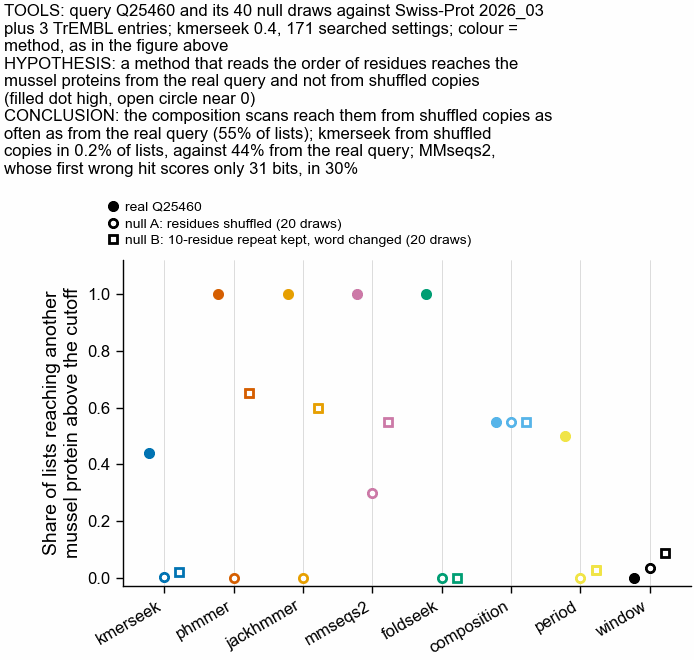

In [13]:
groups = at_cut.with_columns(
    group=pl.when(pl.col("target_lineage").str.starts_with("B1"))
    .then(pl.lit("mussels"))
    .when(pl.col("target_lineage").str.starts_with("B2"))
    .then(pl.lit("sandcastle worm"))
    .otherwise(pl.lit("barnacles"))
)
# Q25460's own entry is not in these counts, for the real query or any draw
# (scripts/convergence_adhesive_q25460_detail.py).
real_reach = groups.filter(pl.col("kind") == "real").with_columns(
    n=pl.col("n_above_real_cutoff")
)
both_settings = per_setting.filter(pl.col("outcome") == "both")["setting_label"]
null_reach = (
    groups.filter(pl.col("kind") != "real")
    .group_by("method", "kind", "group")
    .agg(
        (pl.col("n_above_real_cutoff") > 0).sum().alias("draw_lists_reaching"),
        pl.len().alias("draw_lists"),
    )
    .sort("method", "group", "kind")
)
print(
    "Null draws that reach any protein of each group at the real query's cutoff, summed"
)
print("over every list of the method (draw_lists = 20 draws x the method's lists):")
print(null_reach.filter(pl.col("draw_lists_reaching") > 0))
print()
print(
    "Worm and barnacle proteins reached above the cutoff, every list, real or null:",
    int(groups.filter(pl.col("group") != "mussels")["n_above_real_cutoff"].sum()),
)
ks_null = (
    groups.filter(
        (pl.col("kind") != "real")
        & (pl.col("group") == "mussels")
        & (pl.col("method") == "kmerseek")
        & pl.col("setting_label").is_in(both_settings.implode())
    )
    .group_by("kind")
    .agg(
        (pl.col("n_above_real_cutoff") > 0).sum().alias("draws_reaching"),
        pl.len().alias("draws"),
    )
    .sort("kind")
)
print()
print(
    f"In the {len(both_settings)} kmerseek settings that put both Mytilus foot protein 1"
)
print("entries first, null draws reaching any mussel protein at the same cutoff:")
print(ks_null)

# Share of each method's lists in which a query reaches at least one other mussel protein
# above the real query's cutoff: the real query, and the 20 draws of each null pooled.
share = (
    pl.concat(
        [
            real_reach.filter(pl.col("group") == "mussels").select(
                "method", "kind", (pl.col("n") > 0).alias("reached")
            ),
            groups.filter(
                (pl.col("kind") != "real") & (pl.col("group") == "mussels")
            ).select(
                "method", "kind", (pl.col("n_above_real_cutoff") > 0).alias("reached")
            ),
        ]
    )
    .group_by("method", "kind")
    .agg(pl.col("reached").mean().alias("share"), pl.len().alias("n_lists"))
    .with_columns(pl.col("method").cast(pl.Enum(METHOD_ORDER)))
    .sort("method", "kind")
)
print()
print(
    "Share of lists reaching at least one other mussel protein above the real cutoff:"
)
print(share)

# Placed by hand, for the same reason as the figure above.
fig = plt.figure(figsize=(pf.ONE_COLUMN_MM * pf.MM, 88 * pf.MM))
ax = fig.add_axes([0.17, 0.16, 0.81, 0.47])
KIND_STYLE = {
    "real": dict(marker="o", fill=True, label="real Q25460"),
    "nullA": dict(marker="o", fill=False, label="null A: residues shuffled (20 draws)"),
    "nullB": dict(
        marker="s",
        fill=False,
        label="null B: 10-residue repeat kept, word changed (20 draws)",
    ),
}
xs = {m: i for i, m in enumerate(methods_run)}
for k, (kind, st) in enumerate(KIND_STYLE.items()):
    sub = share.filter(pl.col("kind") == kind)
    for m, v in zip(sub["method"], sub["share"]):
        c = METHOD_COLOUR[str(m)]
        ax.plot(
            xs[str(m)] + (k - 1) * 0.22,
            v,
            st["marker"],
            color=c,
            markerfacecolor=c if st["fill"] else "white",
            markeredgecolor=c,
            markersize=3,
            linestyle="none",
        )
for kind, st in KIND_STYLE.items():
    ax.plot(
        [],
        [],
        st["marker"],
        color="black",
        markerfacecolor="black" if st["fill"] else "white",
        markersize=3,
        linestyle="none",
        label=st["label"],
    )
ax.set_xticks(range(len(methods_run)))
ax.set_xticklabels(methods_run, rotation=30, ha="right")
ax.set_ylim(-0.03, 1.12)
ax.set_ylabel("Share of lists reaching another\nmussel protein above the cutoff")
ax.grid(axis="x", which="major")
ax.set_axisbelow(True)
ax.legend(
    loc="lower left",
    bbox_to_anchor=(-0.05, 1.01),
    frameon=False,
    fontsize=5,
    handletextpad=0.3,
)
null_header = [
    "query Q25460 and its 40 null draws against Swiss-Prot 2026_03 plus 3 TrEMBL entries; "
    "kmerseek 0.4, 171 searched settings; colour = method, as in the figure above",
    "a method that reads the order of residues reaches the mussel proteins from the real "
    "query and not from shuffled copies (filled dot high, open circle near 0)",
    "the composition scans reach them from shuffled copies as often as from the real query "
    "(55% of lists); kmerseek from shuffled copies in "
    f"{float(share.filter((pl.col('method') == 'kmerseek') & (pl.col('kind') == 'nullA'))['share'][0]):.1%}"
    " of lists, against 44% from the real query; MMseqs2, whose first wrong hit scores "
    "only 31 bits, in 30%",
]
lines = []
for label, text in zip(["TOOLS", "HYPOTHESIS", "CONCLUSION"], null_header):
    lines += textwrap.wrap(f"{label}: {text}", int(fig.get_figwidth() * 25.4 / 1.3))
fig.text(0.0, 1.0, "\n".join(lines), ha="left", va="top", fontsize=6)
pf.save(fig, FIGURES / "295_SF9_q25460_null_draws_mussel_reach_swissprot_2026_03")

print()
print("The first wrong protein of each non-kmerseek list (the Q25460 query):")
print(
    first_fp.filter(pl.col("method") != "kmerseek")
    .with_columns(pl.col("method").cast(pl.Enum(METHOD_ORDER)))
    .sort("method", "setting_label")
    .select(
        "method", "setting_label", "first_fp_rank", "first_fp_target", "first_fp_name"
    )
)
print()
print(
    "Top 20 of the Dayhoff composition scan, the list that ranks the worm cement highest:"
)
print(
    top_hits.filter(pl.col("setting_label") == "composition_dayhoff6").select(
        "rank", "target", "truth_lineage", "protein_name"
    )
)

## Summary and conclusions

**Verdict: FAIL.** No kmerseek setting reaches ice-binding proteins of another lineage
better than a scan that needs no search. Neither held-out lineage passes, and the rule
needs both.

The three numbers of the rule, for the chosen setting hsdm17 k=6 scaled=1 with mismatch
penalty 0.18, picked on the four in-sample lineages where its mean cross-lineage recall
was 0.0227:

| Held-out lineage | kmerseek recall | best scan with no search | margin (needs >= 0.10) |
|---|---|---|---|
| 2 fish, AFGP | 0.000 | 0.127 (composition in the wass14 alphabet) | -0.127 |
| 4 fish, type III | 0.000 | 0.000 | 0.000 |

**Claim sentences.**

1. Over 164 searchable settings and six queries, kmerseek reached an ice-binding protein
   of another lineage from one query only, the bacterial one, finding 5 of 55 (recall
   0.091); phmmer, jackhmmer, MMseqs2 and Foldseek each found the same 5, so kmerseek
   added nothing there.
2. Those 5 proteins and the query all carry UniProt's "Ice-binding protein family"
   annotation, so the one place any method crossed a lineage boundary is a family related
   by ancestry, not a pattern shared without it.
3. From the five fish and insect queries, no kmerseek setting reached any ice-binding
   protein of another lineage: 0 of 164 settings for each query. From the bacterial
   query, 24 of the 164 settings reached at least one.
4. The only cross-lineage reach that ordinary sequence search misses came from a method
   with no search: the composition scan in the wass14 alphabet reached 7 of 55 fish type I
   proteins from the AFGP query, where every kmerseek setting reached 0. All 40 control
   draws of that query reached the same 7, as they must: a shuffle keeps the composition,
   so this reach comes from the AFGP query's alanine- and threonine-rich composition, not
   from the order of its residues.
5. The Kyte-Doolittle hydropathy window reached nothing from any real query, in any of its
   10 lists.
6. For the kmerseek setting the rule chose, every control draw reached 0 ice-binding
   proteins at the real query's score cutoff. The null rule is satisfied only because the
   real counts are 0 too, so it says nothing here.

**What this decides.** The paper cannot claim from this test that kmerseek finds proteins
sharing a physicochemical pattern without shared ancestry. The one cross-lineage pair it
reaches is a homolog pair that four other tools also find.

**What this test cannot say.** Four limits, each visible in the data above:

* Plants have no reviewed ice-binding protein, so the held-out half is two lineages, both
  fish, and the rule needed both.
* 44 of the 59 truth entries are fish, so most of the possible cross-lineage reach is
  between fish types, which arose from different genes but in one lineage.
* 66 of the 230 settings could not be searched at all, their Karlin-Altschul fit refused,
  so the sweep is 164 settings wide, not 230.
* A single query per lineage was chosen by its count of experimental evidence lines. A
  different query from the same lineage could behave differently, and nothing here tests
  that.

**Why no setting could have passed.** Section 9 counts shared k-mers directly, the bar
a target must clear before kmerseek reports it at all. While at most 1% of random
Swiss-Prot entries clear it, no query shares 2 k-mers with more than 6 ice-binding
proteins of another lineage, in any of the 8 alphabets checked at any k from 3 to 40. The
6 are reached from the AFGP query in the 20-letter alphabet at k = 4; at k = 7 it is 4
fish type I proteins that carry the AFGP repeat's own letters, AATAATA. Every hydrophobic-polar alphabet reaches other-lineage
ice-binding proteins no more often than random proteins. The settings run were the
dark-set ones, whose shortest hydrophobic-polar k is 17, but shorter k does not help
either.

**Adhesive case study: mussel foot protein 1 (section 11).** Q25460 as the query, all
230 kmerseek settings, every other method, and 40 null draws.

7. No kmerseek setting, and no sequence tool (phmmer, jackhmmer, MMseqs2), reported
   either sandcastle worm cement protein or either barnacle cement protein at any score.
   Foldseek did not either. The only lists that rank a worm cement protein near the top
   are composition scans: the Dayhoff 6-letter composition ranks Pc-2 27th and Pc-1
   59th, behind 21 and 52 proteins that are not adhesives. 15 of those are in its top 20,
   all bradykinin peptides (9 residues, rich in proline and arginine) and one
   bradykinin-like earthworm peptide, megascoliakinin; Dayhoff's alphabet puts arginine and
   lysine in one group. A shuffle keeps composition, so the null A draws rank them the same
   way.
8. Every sequence tool, Foldseek and 39 of the 230 kmerseek settings put the two
   *Mytilus* foot protein 1 entries (Q25434, Q27409) first, before any protein that is
   not an adhesive. In those 39 settings no shuffled draw reached a mussel protein at the
   same score (0 of 780), and draws that keep the 10-residue repeat reached one in 39 of
   780. So kmerseek's reach there depends on the order of the residues, as a homolog
   search's should.
9. 36 more settings gave none of Q25460's hits an E-value (E = infinity, a region score
   of 0 bits), so they rank nothing; 27 of them reported only the three foot protein 1
   entries. 59 had the E-value fit
   refused. kmerseek reports the *Perna viridis* foot protein 1 variants only with no
   E-value, tied with about 12,800 proteins that are not adhesives (hp_kyte_doolittle2,
   k = 33), while Foldseek on the AlphaFold models and the hydrophobic-moment period scan
   each rank variant 1 behind 4. Foot protein 2 comes no closer than 1,684 wrong proteins
   in any kmerseek setting (the 20 amino acids, k = 5).

**What this decides.** By the rule in section 11, the adhesive class is not worth a
benchmark built from TrEMBL entries: nothing kmerseek ranks reaches the worm cement
proteins. The case study adds a second pattern class where kmerseek finds the homologs
any search finds and nothing further.

**Next.** The ice-binding test is the only class run as a benchmark. Section 8 shows the
truth sets for the other three classes: only the shell-matrix class has enough reviewed
entries to be scored as a benchmark; adhesive and silk proteins can only be case studies.

**The shell-matrix class is not worth a search as built (section 10).** Its targets were
chosen by composition, so the composition rule reaches all of them at 4.5% of random
proteins, while at that cost the best k-mer setting reaches 37 of 72 from one query and 5
of 9 from the vertebrate one. The k-mers it does share across
lineages are long, nearly all-polar runs in the hydrophobic-polar alphabets, which is low
complexity again. And 66 of its 75 targets are vertebrate, with 3 in each other lineage.
A search would be worth running only on a truth set defined by function rather than
composition.